In [1]:
import os
import numpy as np
import torch
import torch.nn as nn
import pickle
import cv2
import time

from torch.utils.data import Dataset, DataLoader
from itertools import permutations

In [2]:
GLOBAL_SEED = 42

np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GLOBAL_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device: ", DEVICE)
print("Seed value: ", GLOBAL_SEED)

Device:  cuda
Seed value:  42


In [3]:
PROJECT_ROOT = os.getcwd()

ARCHIVE_DIRECTORY = os.path.join(PROJECT_ROOT, "archive")

MNIST_DIRECTORY = os.path.join(ARCHIVE_DIRECTORY, "mnist")
CIFAR10_DIRECTORY = os.path.join(ARCHIVE_DIRECTORY, "cifar10")
FRUITS360_DIRECTORY = os.path.join(ARCHIVE_DIRECTORY, "fruits360")

CHECKPOINT_DIRECTORY = os.path.join(PROJECT_ROOT, "checkpoints")
RESULTS_DIRECTORY = os.path.join(PROJECT_ROOT, "results")

directories = [MNIST_DIRECTORY, CIFAR10_DIRECTORY, FRUITS360_DIRECTORY, CHECKPOINT_DIRECTORY, RESULTS_DIRECTORY]

for directory in directories:
    os.makedirs(directory, exist_ok=True)

In [4]:
MNIST_FILE_PATHS = {
    "train_images": os.path.join(MNIST_DIRECTORY, "train-images.idx3-ubyte"),
    "train_labels": os.path.join(MNIST_DIRECTORY, "train-labels.idx1-ubyte"),
    "test_images": os.path.join(MNIST_DIRECTORY, "t10k-images.idx3-ubyte"),
    "test_labels": os.path.join(MNIST_DIRECTORY, "t10k-labels.idx1-ubyte")
}

In [5]:
def read_idx_images(file_path):
    with open(file_path, "rb") as file:
        magic_number = int.from_bytes(file.read(4), byteorder="big")
        number_of_images = int.from_bytes(file.read(4), byteorder="big")
        number_of_rows = int.from_bytes(file.read(4), byteorder="big")
        number_of_columns = int.from_bytes(file.read(4), byteorder="big")

        image_data = np.frombuffer(file.read(), dtype=np.uint8).copy()

    if magic_number != 2051:
        raise ValueError("Invalid IDX image file.")

    expected_size = (number_of_images * number_of_rows * number_of_columns)

    if image_data.size != expected_size:
        raise ValueError("Image data size does not match the IDX header.")

    return image_data.reshape(number_of_images, 1, number_of_rows, number_of_columns)


In [6]:
def read_idx_labels(file_path):
    with open(file_path, "rb") as file:
        magic_number = int.from_bytes(file.read(4), byteorder="big")
        number_of_labels = int.from_bytes(file.read(4), byteorder="big")

        label_data = np.frombuffer(file.read(), dtype=np.uint8)

    if magic_number != 2049:
        raise ValueError("Invalid IDX label file.")

    if label_data.size !=number_of_labels:
        raise ValueError("Label data size does not match the IDX header.")

    return label_data

In [7]:
def load_mnist(file_paths):
    train_images = read_idx_images(file_paths["train_images"])
    train_labels = read_idx_labels(file_paths["train_labels"])

    test_images = read_idx_images(file_paths["test_images"])
    test_labels = read_idx_labels(file_paths["test_labels"])

    if train_images.shape[0] != train_labels.shape[0]:
        raise ValueError("Training image and label counts do not match.")

    if test_images.shape[0] != test_labels.shape[0]:
        raise ValueError("Test image and label count do not match.")

    dataset_information = {
        "dataset_name": "mnist",
        "input_shape": train_images.shape[1:],
        "number_of_classes": len(np.unique(train_labels))
    }

    return (train_images, train_labels, test_images, test_labels, dataset_information)

(train_images, train_labels, test_images, test_labels, dataset_information) = load_mnist(MNIST_FILE_PATHS)

In [8]:
def create_stratified_split_indices(labels, seed, validation_per_class=None, validation_ratio=None):
    if(validation_per_class is None) == (validation_ratio is None):
        raise ValueError("Provide either validation_per_class or validation_ratio.")

    random_generator = np.random.default_rng(seed)

    train_indices = []
    validation_indices = []

    for class_label in np.unique(labels):
        class_indices = np.where(labels == class_label)[0]
        random_generator.shuffle(class_indices)

        if validation_per_class is not None:
            validation_count = validation_per_class
        else:
            validation_count = round(len(class_indices) * validation_ratio)

        if validation_count <= 0 or validation_count >= len(class_indices):
            raise ValueError("Validation size must be between zero and the class size.")

        validation_indices.extend(class_indices[:validation_count])
        train_indices.extend(class_indices[validation_count:])

    train_indices = np.array(train_indices)
    validation_indices = np.array(validation_indices)

    random_generator.shuffle(train_indices)
    random_generator.shuffle(validation_indices)

    return train_indices, validation_indices

In [9]:
VALIDATION_PER_CLASS = 1000

train_indices, validation_indices = create_stratified_split_indices(labels=train_labels, seed=GLOBAL_SEED, validation_per_class=VALIDATION_PER_CLASS)

training_images = train_images[train_indices]
training_labels = train_labels[train_indices]

validation_images = train_images[validation_indices]
validation_labels = train_labels[validation_indices]

if len(training_images) + len(validation_images) != len(train_images):
    raise ValueError("Train-validation split size is incorrect.")

if len(np.intersect1d(train_indices, validation_indices)) != 0:
    raise ValueError("Tran and validation indices overlap.") 

In [10]:
class ImageDataset(Dataset):
    def __init__(self, images, labels, pixel_scale=255.0, channel_mean=None, channel_standard_deviation=None):

        if isinstance(images, np.ndarray):
            images = torch.from_numpy(images)
        if not torch.is_tensor(images):
            raise TypeError("Images must be a NumPy array or a PyTorch tensor.")
        if images.ndim == 3:
            images = images.unsqueeze(1)
        if images.ndim != 4:
            raise ValueError("Images must have shape [N, C, H, W] or [N, H, W].")

        labels = torch.as_tensor(labels, dtype=torch.long)

        if len(images) != len(labels):
            raise ValueError("Image and label counts do not match.")
        if pixel_scale <= 0:
            raise ValueError("Pixel scale must be greater than zero.")
        if (channel_mean is None) != (channel_standard_deviation is None):
            raise ValueError("Channel mean and standard deviation must be provided together.")

        self.images = images
        self.labels = labels
        self.pixel_scale = float(pixel_scale)

        if channel_mean is None:
            self.channel_mean = None
            self.channel_standard_deviation = None
        else:
            self.channel_mean = torch.as_tensor(channel_mean, dtype=torch.float32).reshape(-1,1,1)
            self.channel_standard_deviation = torch.as_tensor(channel_standard_deviation, dtype=torch.float32).reshape(-1,1,1)

            if len(self.channel_mean) != images.shape[1]:
                raise ValueError("Normalization values must match the number of image channels.")
            if torch.any(self.channel_standard_deviation <= 0):
                raise ValueError("Channel standard deviations must be greater than zero.")
    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.images[index], self.labels[index]          

In [11]:
def prepare_image_datasets(training_images, training_labels, validation_images, validation_labels, test_images, test_labels, class_names, dataset_name):
    channel_sum = np.zeros(training_images.shape[1], dtype=np.float64)
    channel_squared_sum = np.zeros(training_images.shape[1], dtype=np.float64)

    pixel_count = (
        len(training_images)
        * training_images.shape[2]
        * training_images.shape[3]
    )

    for start in range(0, len(training_images), 256):
        batch = training_images[start:start + 256].astype(np.float64)

        channel_sum += batch.sum(axis=(0, 2, 3))
        channel_squared_sum += (batch ** 2).sum(axis=(0, 2, 3))

    mean = channel_sum / pixel_count

    std = np.sqrt(
        channel_squared_sum / pixel_count
        - mean ** 2
    )

    mean = mean / 255.0
    std = std / 255.0

    dataset_kwargs = {
        "channel_mean": mean,
        "channel_standard_deviation": std
    }

    training_dataset = ImageDataset(training_images, training_labels, **dataset_kwargs)
    validation_dataset = ImageDataset(validation_images, validation_labels, **dataset_kwargs)

    test_dataset = None

    if test_images is not None and test_labels is not None:
        test_dataset = ImageDataset(test_images, test_labels, **dataset_kwargs)
    
    information = {
        "dataset_name": dataset_name,
        "input_shape": tuple(training_images.shape[1:]),
        "number_of_classes": len(class_names),
        "class_names": class_names,
        "training_size": len(training_dataset),
        "validation_size": len(validation_dataset),
        "test_size": 0 if test_dataset is None else len(test_dataset),
        "channel_mean": mean.tolist(),
        "channel_standard_deviation": std.tolist()
    }

    return (training_dataset, validation_dataset, test_dataset, information, dataset_kwargs)

In [12]:
def load_image_folder_split(root_directory, split_name, class_names=None):
    matches = [
        os.path.join(current_directory, directory)
        for current_directory, directories, _ in os.walk(root_directory)
        for directory in directories
        if directory.lower() == split_name.lower()
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Expected one {split_name} directory, found {len(matches)}."
        )

    split_directory = matches[0]

    if class_names is None:
        class_names = sorted(
            name for name in os.listdir(split_directory)
            if os.path.isdir(os.path.join(split_directory, name))
        )

    class_to_index = {
        name: index
        for index, name in enumerate(class_names)
    }

    image_paths = []
    labels = []

    for class_name in class_names:
        class_directory = os.path.join(split_directory, class_name)

        if not os.path.isdir(class_directory):
            continue

        for file_name in sorted(os.listdir(class_directory)):
            file_path = os.path.join(class_directory, file_name)

            image_paths.append(file_path)
            labels.append(class_to_index[class_name])

    if len(image_paths) == 0:
        raise ValueError(f"No images found in {split_directory}.")

    first_image = cv2.imread(image_paths[0])

    if first_image is None:
        raise ValueError(f"Could not read image: {image_paths[0]}")

    first_image = cv2.cvtColor(first_image, cv2.COLOR_BGR2RGB)
    image_shape = first_image.transpose(2, 0, 1).shape

    images = np.empty(
        (len(image_paths), *image_shape),
        dtype=first_image.dtype
    )

    valid_labels = np.empty(
        len(image_paths),
        dtype=np.int64
    )

    valid_count = 0

    for file_path, label in zip(image_paths, labels):
        image = cv2.imread(file_path)

        if image is None:
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = image.transpose(2, 0, 1)

        if image.shape != image_shape:
            raise ValueError(f"Inconsistent image shape: {file_path}")

        images[valid_count] = image
        valid_labels[valid_count] = label
        valid_count += 1

    return (
        images[:valid_count],
        valid_labels[:valid_count],
        class_names
    )

In [13]:
training_dataset = ImageDataset(training_images, training_labels)
validation_dataset = ImageDataset(validation_images, validation_labels)
test_dataset = ImageDataset(test_images, test_labels)

<local-home>\AppData\Local\Temp\ipykernel_27948\2881974888.py:13: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  labels = torch.as_tensor(labels, dtype=torch.long)


In [14]:
def create_data_loaders(training_dataset, validation_dataset, test_dataset, training_batch_size, evaluation_batch_size, seed, num_workers=0, pin_memory=False):
    generator = torch.Generator()
    generator.manual_seed(seed)

    common_loader_kwargs = {
        "num_workers": num_workers,
        "pin_memory": pin_memory
    }

    if num_workers > 0:
        common_loader_kwargs["persistent_workers"] = True
        common_loader_kwargs["prefetch_factor"] = 2

    training_loader = DataLoader(
        training_dataset,
        batch_size=training_batch_size,
        shuffle=True,
        generator=generator,
        **common_loader_kwargs
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=evaluation_batch_size,
        shuffle=False,
        **common_loader_kwargs
    )
        
    test_loader = None

    if test_dataset is not None:
        test_loader = DataLoader(
            test_dataset,
            batch_size=evaluation_batch_size,
            shuffle=False,
            **common_loader_kwargs
        )

    return training_loader, validation_loader, test_loader

In [15]:
class DynamicMLP(nn.Module):
    def __init__(self, input_shape, number_of_classes, hidden_sizes, activation_name, use_batch_normalization, dropout_rate):
        super().__init__()

        input_size = int(np.prod(input_shape))
        layers = []
        previous_size = input_size

        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(previous_size, hidden_size))

            if use_batch_normalization:
                layers.append(nn.BatchNorm1d(hidden_size))

            if activation_name == "relu":
                layers.append(nn.ReLU())
            elif activation_name == "tanh":
                layers.append(nn.Tanh())
            elif activation_name == "elu":
                layers.append(nn.ELU())
            else:
                raise ValueError("Unsupported activation function.")

            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))

            previous_size = hidden_size

        layers.append(nn.Linear(previous_size, number_of_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, images):
        flatten_images = torch.flatten(images, start_dim=1)

        return self.network(flatten_images)

In [16]:
def train_one_epoch(model, data_loader, loss_function, optimizer, device):
    model.train()

    total_loss = 0.0
    correct_predictions = 0
    total_sample = 0

    pixel_scale = data_loader.dataset.pixel_scale
    channel_mean = data_loader.dataset.channel_mean
    channel_standard_deviation = data_loader.dataset.channel_standard_deviation

    if channel_mean is not None:
        channel_mean = channel_mean.to(device)
        channel_standard_deviation = channel_standard_deviation.to(device)

    for images, labels in data_loader:
        images = images.to(
            device=device,
            dtype=torch.float32,
            non_blocking=True
        )
        labels = labels.to(device, non_blocking=True)

        images.div_(pixel_scale)

        if channel_mean is not None:
            images.sub_(channel_mean).div_(channel_standard_deviation)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = loss_function(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.detach() * batch_size
        correct_predictions += (outputs.argmax(dim=1) == labels).sum()
        total_sample += batch_size

    average_loss = (total_loss / total_sample).item()
    accuracy = (correct_predictions / total_sample).item()

    return average_loss, accuracy

In [17]:
def evaluate_model(model, data_loader, loss_function, device):
    model.eval()

    total_loss = 0.0
    correct_predictions = 0
    total_sample = 0

    pixel_scale = data_loader.dataset.pixel_scale
    channel_mean = data_loader.dataset.channel_mean
    channel_standard_deviation = data_loader.dataset.channel_standard_deviation

    if channel_mean is not None:
        channel_mean = channel_mean.to(device)
        channel_standard_deviation = channel_standard_deviation.to(device)

    with torch.inference_mode():
        for images, labels in data_loader:
            images = images.to(
                device=device,
                dtype=torch.float32,
                non_blocking=True
            )
            labels = labels.to(device, non_blocking=True)

            images.div_(pixel_scale)

            if channel_mean is not None:
                images.sub_(channel_mean).div_(channel_standard_deviation)

            outputs = model(images)
            loss = loss_function(outputs, labels)

            batch_size = labels.size(0)

            total_loss += loss * batch_size
            correct_predictions += (outputs.argmax(dim=1) == labels).sum()
            total_sample += batch_size

    average_loss = (total_loss / total_sample).item()
    accuracy = (correct_predictions / total_sample).item()

    return average_loss, accuracy

In [18]:
def train_model(model, training_loader, validation_loader, loss_function, optimizer, device, maximum_epochs, early_stopping=False, patience=None):

    if maximum_epochs <= 0:
        raise ValueError("Maximum epochs must be greater than zero.")
    if early_stopping and (patience is None or patience <= 0):
        raise ValueError("Patience must be greater than zero when early stopping is enabled.")
    
    history = {
            "training_loss": [],
            "training_accuracy": [],
            "validation_loss": [],
            "validation_accuracy": []
    }

    best_validation_loss = float("inf")
    best_validation_accuracy = 0.0
    best_epoch = 0
    best_model_state = None
    epochs_without_improvement = 0
    
    for epoch in range(1, maximum_epochs + 1):
            epoch_start_time = time.perf_counter()

            training_loss, training_accuracy = train_one_epoch(
                model=model,
                data_loader=training_loader,
                loss_function=loss_function,
                optimizer=optimizer,
                device=device
            )
    
            validation_loss, validation_accuracy = evaluate_model(
                model=model,
                data_loader=validation_loader,
                loss_function=loss_function,
                device=device
            )
    
            history["training_loss"].append(training_loss)
            history["training_accuracy"].append(training_accuracy)
            history["validation_loss"].append(validation_loss)
            history["validation_accuracy"].append(validation_accuracy)

            epoch_time = time.perf_counter() - epoch_start_time
            
            print(
                f"Epoch {epoch}/{maximum_epochs} | "
                f"train_acc={training_accuracy:.4f} | "
                f"val_acc={validation_accuracy:.4f} | "
                f"val_loss={validation_loss:.4f} | "
                f"time={epoch_time:.1f}s"
            )
    
            if validation_loss < best_validation_loss:
                best_validation_loss = validation_loss
                best_validation_accuracy = validation_accuracy
                best_epoch = epoch
    
                best_model_state = {
                    parameter_name: parameter.detach().cpu().clone()
                    for parameter_name, parameter in model.state_dict().items()               
                }
    
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1
    

            if early_stopping and epochs_without_improvement >= patience:
                print(f"Early stopping at epoch {epoch}.")
                break

    if early_stopping:
        model.load_state_dict(best_model_state)

    training_result = {
        "history": history,
        "training_mode": ("early_stopping" if early_stopping else "fixed_epochs"),
        "best_epoch": best_epoch,
        "best_validation_loss": best_validation_loss,
        "best_validation_accuracy": best_validation_accuracy,
        "last_validation_loss": history["validation_loss"][-1],
        "last_validation_accuracy": history["validation_accuracy"][-1],
        "epochs_completed": len(history["training_loss"])
    }

    
    return training_result

def train_with_early_stopping(model, training_loader, validation_loader, loss_function, optimizer, device, maximum_epochs, patience):

    return train_model(
        model=model,
        training_loader=training_loader,
        validation_loader=validation_loader,
        loss_function=loss_function,
        optimizer=optimizer,
        device=device,
        maximum_epochs=maximum_epochs,
        early_stopping=True,
        patience=patience
    )
    
def train_for_fixed_epochs(model,training_loader,validation_loader,loss_function,optimizer,device,number_of_epochs):
    return train_model(
        model=model,
        training_loader=training_loader,
        validation_loader=validation_loader,
        loss_function=loss_function,
        optimizer=optimizer,
        device=device,
        maximum_epochs=number_of_epochs,
        early_stopping=False
    )

In [19]:
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [20]:
def run_mlp_experiment(training_dataset, validation_dataset, test_dataset, input_shape, number_of_classes, model_config, training_config, seed, device):
    set_seed(seed)

    (training_loader, validation_loader, test_loader) = create_data_loaders(
        training_dataset=training_dataset,
        validation_dataset=validation_dataset,
        test_dataset=test_dataset,
        training_batch_size=training_config["batch_size"],
        evaluation_batch_size=training_config["evaluation_batch_size"],
        seed=seed,
        num_workers=training_config["num_workers"],
        pin_memory=training_config["pin_memory"]
    ) 

    model = DynamicMLP(
        input_shape=input_shape,
        number_of_classes=number_of_classes,
        hidden_sizes=model_config["hidden_sizes"],
        activation_name=model_config["activation_name"],
        use_batch_normalization=model_config["use_batch_normalization"],
        dropout_rate=model_config["dropout_rate"]
    ).to(device)

    class_counts = torch.bincount(
        training_dataset.labels,
        minlength=number_of_classes
    ).to(torch.float32)

    class_weights = None

    if not torch.all(class_counts == class_counts[0]):
        class_weights = (
            len(training_dataset)
            / (number_of_classes * class_counts)
        ).to(device)

    loss_function = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=training_config["learning_rate"])

    training_result = train_with_early_stopping(
        model=model,
        training_loader=training_loader,
        validation_loader=validation_loader,
        loss_function=loss_function,
        optimizer=optimizer,
        device=device,
        maximum_epochs=training_config["maximum_epochs"],
        patience=training_config["patience"]
    )

    experiment_result = {
        "seed": seed,
        "model_config": model_config.copy(),
        "training_config": training_config.copy(),
        **training_result
    }

    return model, experiment_result, test_loader

In [21]:
def generate_mlp_coarse_config(random_generator):
    hidden_layer_count = random_generator.integers(1,4)

    hidden_sizes = random_generator.choice([64, 128, 256, 512], size=hidden_layer_count, replace=True)
    hidden_sizes = sorted(hidden_sizes.tolist(), reverse=True)

    learning_rate = 10 ** random_generator.uniform(-4, -2.5)

    model_config = {
        "hidden_sizes": hidden_sizes,
        "activation_name": random_generator.choice(["relu", "tanh"]),
        "use_batch_normalization": bool(random_generator.integers(0,2)),
        "dropout_rate": float(random_generator.uniform(0.0, 0.5))
    } 

    training_config = {
        "batch_size": int(random_generator.choice([128, 256, 512])),
        "evaluation_batch_size": 1024,
        "learning_rate": float(learning_rate),
        "maximum_epochs": 25,
        "patience": int(random_generator.choice([4, 5, 6])),
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda"
    }

    return model_config, training_config

In [22]:
def run_mlp_coarse_search(trial_count, training_dataset, validation_dataset, test_dataset, input_shape, number_of_classes, search_seed, experiment_seed, device, results_file_path):
    random_generator = np.random.default_rng(search_seed)
    coarse_results = []

    for trial_index in range(1, trial_count + 1):
        model_config, training_config = generate_mlp_coarse_config(random_generator)

        _, experiment_result, _ =  run_mlp_experiment(
            training_dataset=training_dataset,
            validation_dataset=validation_dataset,
            test_dataset=test_dataset,
            input_shape=input_shape,
            number_of_classes=number_of_classes,
            model_config=model_config,
            training_config=training_config,
            seed=experiment_seed,
            device=device
        ) 

        experiment_result["trial"] = trial_index
        coarse_results.append(experiment_result)

        torch.save(coarse_results, results_file_path)

    coarse_results.sort(
        key=lambda result: (
            result["best_validation_accuracy"], -result["best_validation_loss"]
        ),
        reverse=True
    )

    torch.save(coarse_results, results_file_path)

    return coarse_results

In [23]:
MLP_COARSE_TRIAL_COUNT = 20
MLP_SEARCH_SEED = 42
MLP_EXPERIMENT_SEED = GLOBAL_SEED

MLP_COARSE_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY, "mnist_mlp_coarse_results.pt")

mlp_coarse_results = run_mlp_coarse_search(
    trial_count=MLP_COARSE_TRIAL_COUNT,
    training_dataset=training_dataset,
    validation_dataset=validation_dataset,
    test_dataset=test_dataset,
    input_shape=dataset_information["input_shape"],
    number_of_classes=dataset_information["number_of_classes"],
    search_seed=MLP_SEARCH_SEED,
    experiment_seed=MLP_EXPERIMENT_SEED,
    device=DEVICE,
    results_file_path=MLP_COARSE_RESULTS_PATH
)

Epoch 1/25 | train_acc=0.9121 | val_acc=0.9523 | val_loss=0.1742 | time=2.0s
Epoch 2/25 | train_acc=0.9561 | val_acc=0.9642 | val_loss=0.1292 | time=1.6s
Epoch 3/25 | train_acc=0.9677 | val_acc=0.9703 | val_loss=0.1083 | time=1.6s
Epoch 4/25 | train_acc=0.9730 | val_acc=0.9730 | val_loss=0.0983 | time=1.5s
Epoch 5/25 | train_acc=0.9774 | val_acc=0.9744 | val_loss=0.0890 | time=1.4s
Epoch 6/25 | train_acc=0.9804 | val_acc=0.9764 | val_loss=0.0828 | time=1.5s
Epoch 7/25 | train_acc=0.9824 | val_acc=0.9763 | val_loss=0.0822 | time=1.5s
Epoch 8/25 | train_acc=0.9851 | val_acc=0.9766 | val_loss=0.0792 | time=1.4s
Epoch 9/25 | train_acc=0.9865 | val_acc=0.9793 | val_loss=0.0769 | time=1.4s
Epoch 10/25 | train_acc=0.9878 | val_acc=0.9793 | val_loss=0.0760 | time=1.4s
Epoch 11/25 | train_acc=0.9881 | val_acc=0.9781 | val_loss=0.0737 | time=1.4s
Epoch 12/25 | train_acc=0.9895 | val_acc=0.9803 | val_loss=0.0737 | time=1.3s
Epoch 13/25 | train_acc=0.9904 | val_acc=0.9804 | val_loss=0.0718 | time=

In [24]:
def generate_mlp_refined_config(center_result, random_generator):
    center_model_config = center_result["model_config"]
    center_training_config = center_result["training_config"]

    refined_hidden_sizes = []

    for center_size in center_model_config["hidden_sizes"]:
        lower_bound = max(32, int(center_size * 0.80))
        upper_bound = min(768, int(center_size * 1.20))
        hidden_size = random_generator.integers(lower_bound, upper_bound+1)
        hidden_size = int(round(hidden_size / 16) * 16)
        refined_hidden_sizes.append(hidden_size)

    refined_hidden_sizes = sorted(refined_hidden_sizes, reverse=True)
    dropout_rate = np.clip(center_model_config["dropout_rate"] + random_generator.uniform(-0.10, 0.10), 0.0, 0.5)
    learning_rate = (center_training_config["learning_rate"] * 10 ** random_generator.uniform(-0.35, 0.35))
    batch_size_options = [128, 256, 512]
    center_batch_index = batch_size_options.index(center_training_config["batch_size"])
    possible_batch_indices = [
        index
        for index in [
            center_batch_index - 1,
            center_batch_index,
            center_batch_index + 1
        ]
        if 0 <= index < len(batch_size_options)
    ]

    batch_size = batch_size_options[random_generator.choice(possible_batch_indices)]

    patience = int(
        np.clip(
            center_training_config["patience"]
            + random_generator.integers(-1, 2),
            4,
            7
        )
    )

    model_config = {
        "hidden_sizes": refined_hidden_sizes,
        "activation_name": center_model_config["activation_name"],
        "use_batch_normalization": center_model_config["use_batch_normalization"],
        "dropout_rate": float(dropout_rate) 
    }

    training_config = {
        "batch_size": batch_size,
        "evaluation_batch_size": 1024,
        "learning_rate": float(learning_rate),
        "maximum_epochs": 35,
        "patience": patience,
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda"
    }

    return model_config, training_config

In [25]:
def run_mlp_refined_search(coarse_results,center_count,trials_per_center,training_dataset,validation_dataset,test_dataset,input_shape,number_of_classes,search_seed,experiment_seed,device,results_file_path):

    random_generator = np.random.default_rng(search_seed)
    center_results = coarse_results[:center_count]
    refined_results = []
    trial_index = 0

    for center_rank, center_result, in enumerate(center_results, start=1):
        for center_trial in range(1, trials_per_center + 1):
            trial_index += 1
            (model_config, training_config) = generate_mlp_refined_config(center_result=center_result, random_generator=random_generator)

            _, experiment_result, _ = run_mlp_experiment(
                training_dataset=training_dataset,                
                validation_dataset=validation_dataset,                
                test_dataset=test_dataset,                
                input_shape=input_shape,
                number_of_classes=number_of_classes,
                model_config=model_config,
                training_config=training_config,
                seed=experiment_seed,
                device=device
            )

            experiment_result["trial"] = trial_index
            experiment_result["center_rank"] = center_rank
            experiment_result["center_trial"] = center_trial
            experiment_result["center_coarse_trial"] = (center_result["trial"])
            refined_results.append(experiment_result)

            torch.save(refined_results, results_file_path)

            print(
                f"Trial {trial_index} | "
                f"Center {center_rank} | "
                f"Validation accuracy: "
                f"{experiment_result['best_validation_accuracy'] * 100:.2f}% | "
                f"Best epoch: {experiment_result['best_epoch']}"
            )

    refined_results.sort(
        key=lambda result: (
            result["best_validation_accuracy"],
            -result["best_validation_loss"]
        ), 
        reverse=True
    )

    torch.save(refined_results, results_file_path)

    return refined_results

In [26]:
MLP_REFINED_CENTER_COUNT = 3
MLP_REFINED_TRIALS_PER_CENTER = 4
MLP_REFINED_SEARCH_SEED = 43

MLP_REFINED_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY, "mnist_mlp_refined_results.pt")

mlp_refined_results = run_mlp_refined_search(
    coarse_results=mlp_coarse_results,
    center_count=MLP_REFINED_CENTER_COUNT,
    trials_per_center=MLP_REFINED_TRIALS_PER_CENTER,
    training_dataset=training_dataset,
    validation_dataset=validation_dataset,
    test_dataset=test_dataset,
    input_shape=dataset_information["input_shape"],
    number_of_classes=dataset_information["number_of_classes"],
    search_seed=MLP_REFINED_SEARCH_SEED,
    experiment_seed=MLP_EXPERIMENT_SEED,
    device=DEVICE,
    results_file_path=MLP_REFINED_RESULTS_PATH
)

Epoch 1/35 | train_acc=0.9094 | val_acc=0.9624 | val_loss=0.1282 | time=2.5s
Epoch 2/35 | train_acc=0.9547 | val_acc=0.9705 | val_loss=0.0950 | time=2.4s
Epoch 3/35 | train_acc=0.9642 | val_acc=0.9743 | val_loss=0.0864 | time=2.3s
Epoch 4/35 | train_acc=0.9689 | val_acc=0.9764 | val_loss=0.0806 | time=2.5s
Epoch 5/35 | train_acc=0.9748 | val_acc=0.9784 | val_loss=0.0752 | time=2.2s
Epoch 6/35 | train_acc=0.9760 | val_acc=0.9800 | val_loss=0.0691 | time=2.2s
Epoch 7/35 | train_acc=0.9786 | val_acc=0.9782 | val_loss=0.0685 | time=2.2s
Epoch 8/35 | train_acc=0.9803 | val_acc=0.9802 | val_loss=0.0655 | time=2.1s
Epoch 9/35 | train_acc=0.9818 | val_acc=0.9808 | val_loss=0.0677 | time=2.5s
Epoch 10/35 | train_acc=0.9824 | val_acc=0.9822 | val_loss=0.0647 | time=2.6s
Epoch 11/35 | train_acc=0.9842 | val_acc=0.9794 | val_loss=0.0717 | time=2.4s
Epoch 12/35 | train_acc=0.9852 | val_acc=0.9813 | val_loss=0.0647 | time=2.2s
Epoch 13/35 | train_acc=0.9857 | val_acc=0.9819 | val_loss=0.0672 | time=

In [27]:
mlp_search_results = (mlp_coarse_results + mlp_refined_results)
mlp_search_results.sort(
    key=lambda result: (
        result["best_validation_accuracy"],
        -result["best_validation_loss"]
    ),
    reverse=True
)

MLP_COMBINED_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY, "mnist_mlp_combined_results.pt")

torch.save(mlp_search_results, MLP_COMBINED_RESULTS_PATH)

best_mlp_search_result = mlp_search_results[0]


In [28]:
MLP_VALIDATION_SEEDS = [42, 52, 62]

best_mlp_model_config = (best_mlp_search_result["model_config"].copy())
best_mlp_training_config = (best_mlp_search_result["training_config"].copy())

mlp_seed_results = []

for seed in MLP_VALIDATION_SEEDS:
    model, seed_result, _ = run_mlp_experiment(
        training_dataset=training_dataset,
        validation_dataset=validation_dataset,
        test_dataset=test_dataset,
        input_shape=dataset_information["input_shape"],
        number_of_classes=dataset_information["number_of_classes"],
        model_config=best_mlp_model_config,
        training_config=best_mlp_training_config,
        seed=seed,
        device=DEVICE
    )

    checkpoint_path = os.path.join(CHECKPOINT_DIRECTORY, f"mnist_mlp_seed_{seed}.pt")
    model_state_dict = {
        parameter_name: parameter.detach().cpu()
        for parameter_name, parameter
        in model.state_dict().items()
    }

    torch.save(
        {
            "model_state_dict": model_state_dict,
            "model_config": best_mlp_model_config,
            "training_config": best_mlp_training_config,
            "seed": seed
        },
        checkpoint_path
    )

    seed_result["checkpoint_path"] = checkpoint_path
    mlp_seed_results.append(seed_result)

MLP_SEED_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY, "mnist_mlp_seed_results.pt")
torch.save(mlp_seed_results, MLP_SEED_RESULTS_PATH)



Epoch 1/35 | train_acc=0.8647 | val_acc=0.9535 | val_loss=0.1734 | time=1.0s
Epoch 2/35 | train_acc=0.9496 | val_acc=0.9689 | val_loss=0.1107 | time=1.0s
Epoch 3/35 | train_acc=0.9626 | val_acc=0.9703 | val_loss=0.0992 | time=1.1s
Epoch 4/35 | train_acc=0.9695 | val_acc=0.9757 | val_loss=0.0838 | time=1.0s
Epoch 5/35 | train_acc=0.9727 | val_acc=0.9763 | val_loss=0.0779 | time=1.0s
Epoch 6/35 | train_acc=0.9772 | val_acc=0.9775 | val_loss=0.0779 | time=1.1s
Epoch 7/35 | train_acc=0.9801 | val_acc=0.9807 | val_loss=0.0708 | time=1.0s
Epoch 8/35 | train_acc=0.9813 | val_acc=0.9795 | val_loss=0.0730 | time=1.0s
Epoch 9/35 | train_acc=0.9838 | val_acc=0.9805 | val_loss=0.0746 | time=1.1s
Epoch 10/35 | train_acc=0.9833 | val_acc=0.9791 | val_loss=0.0710 | time=1.0s
Epoch 11/35 | train_acc=0.9846 | val_acc=0.9803 | val_loss=0.0688 | time=1.0s
Epoch 12/35 | train_acc=0.9864 | val_acc=0.9814 | val_loss=0.0671 | time=0.9s
Epoch 13/35 | train_acc=0.9864 | val_acc=0.9827 | val_loss=0.0674 | time=

In [29]:
validation_accuracies = np.array([
    result["best_validation_accuracy"]
    for result in mlp_seed_results
])

validation_losses = np.array([
    result["best_validation_loss"]
    for result in mlp_seed_results
])

mlp_seed_summary = {
    "validation_accuracy_mean": float(validation_accuracies.mean()),
    "validation_accuracy_std": float(validation_accuracies.std(ddof=1)),
    "validation_loss_mean": float(validation_losses.mean()),
    "validation_loss_std": float(validation_losses.std(ddof=1))
}

FINAL_RAW_MLP_SEED = GLOBAL_SEED

selected_mlp_seed_result = next(
    result
    for result in mlp_seed_results
    if result["seed"] == FINAL_RAW_MLP_SEED
)

MLP_SEED_SUMMARY_PATH = os.path.join(RESULTS_DIRECTORY, "mnist_mlp_seed_summary.pt")

torch.save(mlp_seed_summary, MLP_SEED_SUMMARY_PATH)

In [30]:
best_mlp_checkpoint = torch.load(
    selected_mlp_seed_result["checkpoint_path"],
    map_location=DEVICE,
    weights_only=False
)

best_raw_mlp_model = DynamicMLP(
    input_shape=dataset_information["input_shape"],
    number_of_classes=dataset_information["number_of_classes"],
    hidden_sizes=best_mlp_checkpoint["model_config"]["hidden_sizes"],
    activation_name=best_mlp_checkpoint["model_config"]["activation_name"],
    use_batch_normalization=best_mlp_checkpoint["model_config"]["use_batch_normalization"],
    dropout_rate=best_mlp_checkpoint["model_config"]["dropout_rate"]
).to(DEVICE)

best_raw_mlp_model.load_state_dict(best_mlp_checkpoint["model_state_dict"])

test_loader = DataLoader(
    test_dataset,
    batch_size=best_mlp_checkpoint["training_config"]["evaluation_batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda"
)

test_loss, test_accuracy = evaluate_model(
    model=best_raw_mlp_model,
    data_loader=test_loader,
    loss_function=nn.CrossEntropyLoss(),
    device=DEVICE
)

raw_mlp_final_result = {
    "selected_seed": selected_mlp_seed_result["seed"],
    "model_config": best_mlp_checkpoint["model_config"],
    "training_config": best_mlp_checkpoint["training_config"],
    "validation_summary": mlp_seed_summary,
    "selected_validation_accuracy":
        selected_mlp_seed_result["best_validation_accuracy"],
    "selected_validation_loss":
        selected_mlp_seed_result["best_validation_loss"],
    "test_accuracy": test_accuracy,
    "test_loss": test_loss,
    "checkpoint_path": selected_mlp_seed_result["checkpoint_path"]
}

RAW_MLP_FINAL_RESULT_PATH = os.path.join(RESULTS_DIRECTORY, "mnist_raw_mlp_final_result.pt")

torch.save(raw_mlp_final_result, RAW_MLP_FINAL_RESULT_PATH)


In [31]:
def resize_image_batch(images, target_height, target_width):
    image_tensor = torch.as_tensor(images, dtype=torch.float32)

    resized_images = nn.functional.interpolate(
        image_tensor, 
        size=(target_height, target_width),
        mode="bilinear",
        align_corners=False,
        antialias=True
    )

    if np.issubdtype(images.dtype, np.integer):
        resized_images = resized_images.round()

    return resized_images.cpu().numpy().astype(images.dtype)


def generate_batch_mosaic_data(images, labels, number_of_synthetic_images, method, seed):
    if images.ndim != 4:
        raise ValueError("Images must have shape [N, C, H, W].")
    if len(images) != len(labels):
        raise ValueError("Image and label counts do not match.")
    if number_of_synthetic_images <= 0:
        raise ValueError("The number of synthetic images must be greater than zero.")

    supported_methods = ["vertical", "horizontal", "grid_2x2"]

    if method not in supported_methods:
        raise ValueError(f"Unsupported mosaic method: {method}")

    image_height = images.shape[2]
    image_width = images.shape[3]

    if image_height < 2 or image_width < 2:
        raise ValueError("Images must be at least 2x2 for mosaic generation.")

    random_generator = np.random.default_rng(seed)

    class_labels = np.unique(labels)
    number_of_classes = len(class_labels)

    images_per_class = number_of_synthetic_images // number_of_classes
    remaining_images = number_of_synthetic_images % number_of_classes

    synthetic_images = np.empty((number_of_synthetic_images, *images.shape[1:]),dtype=images.dtype)
    synthetic_labels = np.empty(number_of_synthetic_images,dtype=labels.dtype)

    top_height = image_height // 2
    bottom_height = image_height - top_height

    left_width = image_width // 2
    right_width = image_width - left_width

    source_count = 4 if method == "grid_2x2" else 2

    start_index = 0

    for class_position, class_label in enumerate(class_labels):
        class_synthetic_count = images_per_class

        if class_position < remaining_images:
            class_synthetic_count += 1
        if class_synthetic_count == 0:
            continue

        class_indices = np.where(labels == class_label)[0]
        selected_indices = random_generator.choice(class_indices, size=(class_synthetic_count, source_count), replace=True)

        source_images = images[selected_indices]

        end_index = start_index + class_synthetic_count
        target_images = synthetic_images[start_index:end_index]

        if method == "vertical":
            left_images = resize_image_batch(
                source_images[:, 0],
                image_height,
                left_width
            )

            right_images = resize_image_batch(
                source_images[:, 1],
                image_height,
                right_width
            )

            target_images[:, :, :, :left_width] = left_images
            target_images[:, :, :, left_width:] = right_images

        elif method == "horizontal":
            top_images = resize_image_batch(
                source_images[:, 0],
                top_height,
                image_width
            )

            bottom_images = resize_image_batch(
                source_images[:, 1],
                bottom_height,
                image_width
            )

            target_images[:, :, :top_height, :] = top_images
            target_images[:, :, top_height:, :] = bottom_images

        else:
            top_left_images = resize_image_batch(
                source_images[:, 0],
                top_height,
                left_width
            )

            top_right_images = resize_image_batch(
                source_images[:,1],
                top_height,
                right_width
            )

            bottom_left_images = resize_image_batch(
                source_images[:, 2],
                bottom_height,
                left_width
            )

            bottom_right_images = resize_image_batch(
                source_images[:, 3],
                bottom_height,
                right_width
            )

            target_images[:, :, :top_height, :left_width] = top_left_images
            target_images[:, :, :top_height, left_width:] = top_right_images
            target_images[:, :, top_height:, :left_width] = bottom_left_images
            target_images[:, :, top_height:, left_width:] = bottom_right_images

        synthetic_labels[start_index: end_index] = class_label
        start_index = end_index

    shuffled_indices = random_generator.permutation(number_of_synthetic_images)

    return (synthetic_images[shuffled_indices], synthetic_labels[shuffled_indices])

In [32]:
def create_synthetic_dataset(images, labels, synthetic_ratio, method, seed, dataset_kwargs=None):
    if synthetic_ratio <= 0:
        raise ValueError("Synthetic ratio must be greater than zero.")
    if dataset_kwargs is None:
        dataset_kwargs = {}

    number_of_synthetic_images = max(1, int(round(len(images) * synthetic_ratio)))

    synthetic_images, synthetic_labels = generate_batch_mosaic_data(
        images=images,
        labels=labels,
        number_of_synthetic_images=number_of_synthetic_images,
        method=method,
        seed=seed
    )

    synthetic_dataset = ImageDataset(synthetic_images, synthetic_labels, **dataset_kwargs)
    synthetic_information = {
        "method": method,
        "synthetic_ratio": float(synthetic_ratio),
        "number_of_synthetic_images": number_of_synthetic_images
    }

    return (synthetic_dataset, synthetic_images, synthetic_labels, synthetic_information)

In [33]:
def run_staged_mlp_experiment(training_images,training_labels,training_dataset,validation_dataset,test_dataset,input_shape,number_of_classes,model_config,synthetic_training_config,real_training_config,synthetic_stages,seed,device, dataset_kwargs=None, class_weights=None):
    set_seed(seed)

    supported_methods = ["vertical", "horizontal", "grid_2x2"]
    if dataset_kwargs is None:
        dataset_kwargs = {}

    model = DynamicMLP(
        input_shape=input_shape,
        number_of_classes=number_of_classes,
        hidden_sizes=model_config["hidden_sizes"],
        activation_name=model_config["activation_name"],
        use_batch_normalization=model_config["use_batch_normalization"],
        dropout_rate=model_config["dropout_rate"]
    ).to(device)

    if class_weights is None:
        class_counts = np.bincount(
        training_labels,
        minlength=number_of_classes
    )

        if not np.all(class_counts == class_counts[0]):
            class_weights = (
                len(training_labels)
                / (number_of_classes * class_counts)
            )

    if class_weights is not None:
        class_weights = torch.as_tensor(
            class_weights,
            dtype=torch.float32,
            device=device
        )

    synthetic_loss_function = nn.CrossEntropyLoss()
    real_loss_function = nn.CrossEntropyLoss(
        weight=class_weights
    )
    synthetic_stage_results = []

    for stage_index, stage in enumerate(synthetic_stages, start=1):
        stage_config = synthetic_training_config.copy()
        stage_config.update(stage.get("training_config", {}))

        stage_seed = stage.get("seed", seed)
        maximum_epochs = stage.get("maximum_epochs", stage_config["maximum_epochs"])
        use_early_stopping = stage.get("early_stopping", False)

        (synthetic_dataset, _, _, synthetic_information) = create_synthetic_dataset(
                images=training_images,
                labels=training_labels,
                synthetic_ratio=stage["synthetic_ratio"],
                method=stage["method"],
                seed=stage_seed,
                dataset_kwargs=dataset_kwargs
        )
        
        (synthetic_loader, synthetic_validation_loader, _) = create_data_loaders(
                training_dataset=synthetic_dataset,
                validation_dataset=validation_dataset,
                test_dataset=test_dataset,
                training_batch_size=stage_config["batch_size"],
                evaluation_batch_size=stage_config["evaluation_batch_size"],
                seed=stage_seed,
                num_workers=stage_config["num_workers"],
                pin_memory=stage_config["pin_memory"]
        )


        optimizer = torch.optim.Adam(
                model.parameters(), 
                lr=stage_config["learning_rate"]
        )

        if use_early_stopping:
            stage_result = train_with_early_stopping(
                    model=model,
                    training_loader=synthetic_loader,
                    validation_loader=synthetic_validation_loader,
                    loss_function=synthetic_loss_function,
                    optimizer=optimizer,
                    device=device,
                    maximum_epochs=maximum_epochs,
                    patience=stage.get("patience", stage_config["patience"])
            )
        else:
            stage_result = train_for_fixed_epochs(
                model=model,
                training_loader=synthetic_loader,
                validation_loader=synthetic_validation_loader,
                loss_function=synthetic_loss_function,
                optimizer=optimizer,
                device=device,
                number_of_epochs=maximum_epochs
            )
    
        synthetic_stage_results.append(
            {
                "stage_index": stage_index,
                "method": stage["method"],
                "synthetic_information": synthetic_information,
                "training_config": stage_config,
                "training_result": stage_result
            }
        )

        
    (real_training_loader, real_validation_loader, test_loader) = create_data_loaders(
        training_dataset=training_dataset,
        validation_dataset=validation_dataset,
        test_dataset=test_dataset,
        training_batch_size=real_training_config["batch_size"],
        evaluation_batch_size=real_training_config["evaluation_batch_size"],
        seed=seed,
        num_workers=real_training_config["num_workers"],
        pin_memory=real_training_config["pin_memory"]
    )
    
    real_optimizer = torch.optim.Adam(
        model.parameters(), 
        lr=real_training_config["learning_rate"]
    )
    
    real_result = train_with_early_stopping(
        model=model,
        training_loader=real_training_loader,
        validation_loader=real_validation_loader,
        loss_function=real_loss_function,
        optimizer=real_optimizer,
        device=device,
        maximum_epochs=real_training_config["maximum_epochs"],
        patience=real_training_config["patience"]
    )

    method_order = tuple(stage["method"] for stage in synthetic_stages)

    synthetic_information = {
        "method": (
            method_order[0]
            if len(method_order) == 1
            else None
        ),
        "method_order": method_order,
        "synthetic_ratio": sum(
            stage["synthetic_information"]["synthetic_ratio"]
            for stage in synthetic_stage_results
        ),
        "number_of_synthetic_images": sum(
            stage["synthetic_information"]["number_of_synthetic_images"]
            for stage in synthetic_stage_results
        )
    }

    experiment_result = {
        "seed": seed,
        "model_config": model_config.copy(),
        "synthetic_training_config": synthetic_training_config.copy(),
        "real_training_config": real_training_config.copy(),
        "synthetic_information": synthetic_information,
        "synthetic_method_order": method_order,
        "synthetic_stage_results": synthetic_stage_results,
        "real_result": real_result
    }

    return model, experiment_result, test_loader

In [34]:
SYNTHETIC_METHODS = ("vertical", "horizontal", "grid_2x2")

METHOD_COMPARISON_RATIO = 0.25
METHOD_COMPARISON_EPOCHS = 15
METHOD_COMPARISON_SEED = GLOBAL_SEED

method_comparison_model_config = (best_mlp_search_result["model_config"].copy())
synthetic_method_training_config = (best_mlp_search_result["training_config"].copy())

real_method_training_config = (best_mlp_search_result["training_config"].copy())

real_method_training_config["maximum_epochs"] = 20
real_method_training_config["patience"] = 4

synthetic_method_results = []

SYNTHETIC_METHOD_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY,"mnist_mlp_synthetic_method_results.pt")

if os.path.exists(SYNTHETIC_METHOD_RESULTS_PATH):
    synthetic_method_results = torch.load(
        SYNTHETIC_METHOD_RESULTS_PATH,
        weights_only=False
    )

completed_methods = {
    result["synthetic_information"]["method"]
    for result in synthetic_method_results
}

for synthetic_method in SYNTHETIC_METHODS:

    if synthetic_method in completed_methods:
        continue

    synthetic_stages = [
        {
            "method": synthetic_method,
            "synthetic_ratio": METHOD_COMPARISON_RATIO,
            "maximum_epochs": METHOD_COMPARISON_EPOCHS,
            "early_stopping": False
        }
    ]

    _, method_result, _ = run_staged_mlp_experiment(
        training_images=training_images,
        training_labels=training_labels,
        training_dataset=training_dataset,
        validation_dataset=validation_dataset,
        test_dataset=test_dataset,
        input_shape=dataset_information["input_shape"],
        number_of_classes=dataset_information["number_of_classes"],
        model_config=method_comparison_model_config,
        synthetic_training_config=synthetic_method_training_config,
        real_training_config=real_method_training_config,
        synthetic_stages=synthetic_stages,
        seed=METHOD_COMPARISON_SEED,
        device=DEVICE
    )

    synthetic_method_results.append(method_result)

    torch.save(synthetic_method_results, SYNTHETIC_METHOD_RESULTS_PATH)

In [35]:
best_synthetic_method_result = max(
    synthetic_method_results,
    key=lambda result : (
        result["real_result"]["best_validation_accuracy"],
        -result["real_result"]["best_validation_loss"]
    )
)

best_synthetic_method = best_synthetic_method_result["synthetic_information"]["method"]

In [36]:
SYNTHETIC_COARSE_RATIOS = [0.10, 0.25, 0.40, 1.00, 1.50, 2.00]
SYNTHETIC_RATIO_SEARCH_SEED = GLOBAL_SEED

SYNTHETIC_COARSE_RATIO_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY, "mnist_mlp_synthetic_coarse_ratio_results.pt")

if os.path.exists(SYNTHETIC_COARSE_RATIO_RESULTS_PATH):
    synthetic_ratio_results = torch.load(
        SYNTHETIC_COARSE_RATIO_RESULTS_PATH,
        weights_only=False
    )
else:
    synthetic_ratio_results = [best_synthetic_method_result]

completed_ratios = {
    result["synthetic_information"]["synthetic_ratio"]
    for result in synthetic_ratio_results
}

for synthetic_ratio in SYNTHETIC_COARSE_RATIOS:
    if any(np.isclose(synthetic_ratio, completed_ratio) for completed_ratio in completed_ratios):
        continue

    synthetic_stages = [
        {
            "method": best_synthetic_method,
            "synthetic_ratio": synthetic_ratio,
            "maximum_epochs": METHOD_COMPARISON_EPOCHS,
            "early_stopping": False
        }
    ]

    _, ratio_result, _ = run_staged_mlp_experiment(
        training_images=training_images,
        training_labels=training_labels,
        training_dataset=training_dataset,
        validation_dataset=validation_dataset,
        test_dataset=test_dataset,
        input_shape=dataset_information["input_shape"],
        number_of_classes=dataset_information["number_of_classes"],
        model_config=method_comparison_model_config,
        synthetic_training_config=synthetic_method_training_config,
        real_training_config=real_method_training_config,
        synthetic_stages=synthetic_stages,
        seed=SYNTHETIC_RATIO_SEARCH_SEED,
        device=DEVICE
    )

    synthetic_ratio_results.append(ratio_result)

    torch.save(synthetic_ratio_results, SYNTHETIC_COARSE_RATIO_RESULTS_PATH)

    synthetic_ratio_results.sort(
        key=lambda result: (
            result["real_result"]["best_validation_accuracy"],
            -result["real_result"]["best_validation_loss"]
        ),
        reverse=True 
    )

    torch.save(synthetic_ratio_results, SYNTHETIC_COARSE_RATIO_RESULTS_PATH)
    

In [37]:
best_coarse_ratio_result = synthetic_ratio_results[0]
best_coarse_ratio = best_coarse_ratio_result["synthetic_information"]["synthetic_ratio"]

coarse_ratio_array = np.array(SYNTHETIC_COARSE_RATIOS, dtype=float)
best_coarse_ratio_index = int(np.argmin(np.abs(coarse_ratio_array - best_coarse_ratio)))

if best_coarse_ratio_index == 0:
    next_ratio = SYNTHETIC_COARSE_RATIOS[1]

    refined_ratios = [
        round(best_coarse_ratio / 2, 3),
        round((best_coarse_ratio + next_ratio) / 2, 3)
    ]
elif best_coarse_ratio_index == (len(SYNTHETIC_COARSE_RATIOS) - 1):
    refined_ratios = [2.50, 3.00, 4.00]
else:
    previous_ratio = SYNTHETIC_COARSE_RATIOS[best_coarse_ratio_index - 1]
    next_ratio = SYNTHETIC_COARSE_RATIOS[best_coarse_ratio_index + 1]
    refined_ratios = [
        round((previous_ratio + best_coarse_ratio) / 2,3),
        round((best_coarse_ratio + next_ratio) / 2,3)
    ]

refined_ratios = sorted(set(refined_ratios))
synthetic_refined_ratio_results = []
SYNTHETIC_REFINED_RATIO_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY, "mnist_mlp_synthetic_refined_ratio_results.pt")

for synthetic_ratio in refined_ratios:

    synthetic_stages = [
        {
            "method": best_synthetic_method,
            "synthetic_ratio": synthetic_ratio,
            "maximum_epochs": METHOD_COMPARISON_EPOCHS,
            "early_stopping": False
        }
    ]
    
    _, ratio_result, _ = run_staged_mlp_experiment(
        training_images=training_images,
        training_labels=training_labels,
        training_dataset=training_dataset,
        validation_dataset=validation_dataset,
        test_dataset=test_dataset,
        input_shape=dataset_information["input_shape"],
        number_of_classes=dataset_information["number_of_classes"],
        model_config=method_comparison_model_config,
        synthetic_training_config=synthetic_method_training_config,
        real_training_config=real_method_training_config,
        synthetic_stages=synthetic_stages,
        seed=SYNTHETIC_RATIO_SEARCH_SEED,
        device=DEVICE
    )

    synthetic_refined_ratio_results.append(ratio_result)

    torch.save(synthetic_refined_ratio_results,SYNTHETIC_REFINED_RATIO_RESULTS_PATH)

all_synthetic_ratio_results = (synthetic_ratio_results + synthetic_refined_ratio_results)
all_synthetic_ratio_results.sort(
    key=lambda result: (
        result["real_result"]["best_validation_accuracy"],
        -result["real_result"]["best_validation_loss"]
    ),
    reverse=True
)

best_synthetic_ratio_result = (all_synthetic_ratio_results[0])

best_synthetic_ratio = best_synthetic_ratio_result["synthetic_information"]["synthetic_ratio"]

SYNTHETIC_COMBINED_RATIO_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY,"mnist_mlp_synthetic_combined_ratio_results.pt")

torch.save(all_synthetic_ratio_results,SYNTHETIC_COMBINED_RATIO_RESULTS_PATH)

Epoch 1/15 | train_acc=0.3988 | val_acc=0.0609 | val_loss=2.3126 | time=0.2s
Epoch 2/15 | train_acc=0.7880 | val_acc=0.0803 | val_loss=2.3390 | time=0.1s
Epoch 3/15 | train_acc=0.8848 | val_acc=0.0841 | val_loss=2.3885 | time=0.1s
Epoch 4/15 | train_acc=0.9328 | val_acc=0.0843 | val_loss=2.4598 | time=0.1s
Epoch 5/15 | train_acc=0.9668 | val_acc=0.0845 | val_loss=2.5553 | time=0.1s
Epoch 6/15 | train_acc=0.9684 | val_acc=0.0848 | val_loss=2.6678 | time=0.1s
Epoch 7/15 | train_acc=0.9800 | val_acc=0.0842 | val_loss=2.7890 | time=0.1s
Epoch 8/15 | train_acc=0.9844 | val_acc=0.0841 | val_loss=2.9167 | time=0.1s
Epoch 9/15 | train_acc=0.9916 | val_acc=0.0854 | val_loss=3.0298 | time=0.1s
Epoch 10/15 | train_acc=0.9916 | val_acc=0.0863 | val_loss=3.1346 | time=0.1s
Epoch 11/15 | train_acc=0.9932 | val_acc=0.0860 | val_loss=3.2199 | time=0.1s
Epoch 12/15 | train_acc=0.9964 | val_acc=0.0864 | val_loss=3.3132 | time=0.1s
Epoch 13/15 | train_acc=0.9968 | val_acc=0.0869 | val_loss=3.3898 | time=

In [38]:
SYNTHETIC_EPOCH_CANDIDATES = [5, 10, 15, 20]

synthetic_epoch_results = []

SYNTHETIC_EPOCH_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY, "mnist_mlp_synthetic_epoch_results.pt")

if os.path.exists(SYNTHETIC_EPOCH_RESULTS_PATH):
    synthetic_epoch_results = torch.load(SYNTHETIC_EPOCH_RESULTS_PATH, weights_only=False)

completed_epochs = {
    result["synthetic_stage_results"][0]["training_result"]["epochs_completed"]
    for result in synthetic_epoch_results
}

for synthetic_epochs in SYNTHETIC_EPOCH_CANDIDATES:
    if synthetic_epochs in completed_epochs:
        continue

    synthetic_stages = [
        {
            "method": best_synthetic_method,
            "synthetic_ratio": best_synthetic_ratio,
            "maximum_epochs": synthetic_epochs,
            "early_stopping": False
        }
    ]

    _, epoch_result, _ = run_staged_mlp_experiment(
        training_images=training_images,
        training_labels=training_labels,
        training_dataset=training_dataset,
        validation_dataset=validation_dataset,
        test_dataset=test_dataset,
        input_shape=dataset_information["input_shape"],
        number_of_classes=dataset_information["number_of_classes"],
        model_config=method_comparison_model_config,
        synthetic_training_config=synthetic_method_training_config,
        real_training_config=real_method_training_config,
        synthetic_stages=synthetic_stages,
        seed=SYNTHETIC_RATIO_SEARCH_SEED,
        device=DEVICE
    )

    synthetic_epoch_results.append(epoch_result)

    torch.save(synthetic_epoch_results, SYNTHETIC_EPOCH_RESULTS_PATH)

synthetic_epoch_results.sort(
    key=lambda result: (
        result["real_result"]["best_validation_accuracy"],
        -result["real_result"]["best_validation_loss"]
    ),
    reverse=True
)

best_synthetic_epoch_result = synthetic_epoch_results[0]

best_synthetic_epochs = (
    best_synthetic_epoch_result[
        "synthetic_stage_results"
    ][0]["training_result"]["epochs_completed"]
)

In [39]:
BASE_SYNTHETIC_LR = synthetic_method_training_config["learning_rate"]

SYNTHETIC_LR_CANDIDATES = [
    BASE_SYNTHETIC_LR * 0.25,
    BASE_SYNTHETIC_LR * 0.50,
    BASE_SYNTHETIC_LR,
    BASE_SYNTHETIC_LR * 2.00
]

SYNTHETIC_LR_RESULTS_PATH = os.path.join(
    RESULTS_DIRECTORY,
    "mnist_mlp_synthetic_lr_results.pt"
)

if os.path.exists(SYNTHETIC_LR_RESULTS_PATH):
    synthetic_lr_results = torch.load(
        SYNTHETIC_LR_RESULTS_PATH,
        weights_only=False
    )
else:
    synthetic_lr_results = [best_synthetic_epoch_result]

completed_learning_rates = {
    result["synthetic_stage_results"][0]["training_config"]["learning_rate"]
    for result in synthetic_lr_results
}

for synthetic_learning_rate in SYNTHETIC_LR_CANDIDATES:
    if any(
        np.isclose(synthetic_learning_rate, completed_lr)
        for completed_lr in completed_learning_rates
    ):
        continue

    synthetic_stages = [
        {
            "method": best_synthetic_method,
            "synthetic_ratio": best_synthetic_ratio,
            "maximum_epochs": best_synthetic_epochs,
            "early_stopping": False,
            "training_config": {
                "learning_rate": synthetic_learning_rate
            }
        }
    ]

    _, learning_rate_result, _ = run_staged_mlp_experiment(
        training_images=training_images,
        training_labels=training_labels,
        training_dataset=training_dataset,
        validation_dataset=validation_dataset,
        test_dataset=test_dataset,
        input_shape=dataset_information["input_shape"],
        number_of_classes=dataset_information["number_of_classes"],
        model_config=method_comparison_model_config,
        synthetic_training_config=synthetic_method_training_config,
        real_training_config=real_method_training_config,
        synthetic_stages=synthetic_stages,
        seed=SYNTHETIC_RATIO_SEARCH_SEED,
        device=DEVICE
    )

    synthetic_lr_results.append(learning_rate_result)

    torch.save(
        synthetic_lr_results,
        SYNTHETIC_LR_RESULTS_PATH
    )

synthetic_lr_results.sort(
    key=lambda result: (
        result["real_result"]["best_validation_accuracy"],
        -result["real_result"]["best_validation_loss"]
    ),
    reverse=True
)

best_synthetic_lr_result = synthetic_lr_results[0]

best_synthetic_learning_rate = (
    best_synthetic_lr_result[
        "synthetic_stage_results"
    ][0]["training_config"]["learning_rate"]
)

In [40]:
BASE_REAL_LR = real_method_training_config["learning_rate"]

REAL_LR_CANDIDATES = [
    BASE_REAL_LR * 0.10,
    BASE_REAL_LR * 0.25,
    BASE_REAL_LR * 0.50,
    BASE_REAL_LR
]

REAL_LR_RESULTS_PATH = os.path.join(
    RESULTS_DIRECTORY,
    "mnist_mlp_real_lr_results.pt"
)

if os.path.exists(REAL_LR_RESULTS_PATH):
    real_lr_results = torch.load(
        REAL_LR_RESULTS_PATH,
        weights_only=False
    )
else:
    real_lr_results = [best_synthetic_lr_result]

completed_real_learning_rates = {
    result["real_training_config"]["learning_rate"]
    for result in real_lr_results
}

for real_learning_rate in REAL_LR_CANDIDATES:
    if any(
        np.isclose(real_learning_rate, completed_lr)
        for completed_lr in completed_real_learning_rates
    ):
        continue

    current_real_training_config = (
        real_method_training_config.copy()
    )

    current_real_training_config["learning_rate"] = (
        real_learning_rate
    )

    synthetic_stages = [
        {
            "method": best_synthetic_method,
            "synthetic_ratio": best_synthetic_ratio,
            "maximum_epochs": best_synthetic_epochs,
            "early_stopping": False,
            "training_config": {
                "learning_rate": best_synthetic_learning_rate
            }
        }
    ]

    _, real_lr_result, _ = run_staged_mlp_experiment(
        training_images=training_images,
        training_labels=training_labels,
        training_dataset=training_dataset,
        validation_dataset=validation_dataset,
        test_dataset=test_dataset,
        input_shape=dataset_information["input_shape"],
        number_of_classes=dataset_information["number_of_classes"],
        model_config=method_comparison_model_config,
        synthetic_training_config=synthetic_method_training_config,
        real_training_config=current_real_training_config,
        synthetic_stages=synthetic_stages,
        seed=GLOBAL_SEED,
        device=DEVICE
    )

    real_lr_results.append(real_lr_result)

    torch.save(
        real_lr_results,
        REAL_LR_RESULTS_PATH
    )

real_lr_results.sort(
    key=lambda result: (
        result["real_result"]["best_validation_accuracy"],
        -result["real_result"]["best_validation_loss"]
    ),
    reverse=True
)

best_real_lr_result = real_lr_results[0]

best_real_learning_rate = (
    best_real_lr_result[
        "real_training_config"
    ]["learning_rate"]
)

best_real_training_config = (
    real_method_training_config.copy()
)

best_real_training_config["learning_rate"] = (
    best_real_learning_rate
)

In [41]:
SEQUENTIAL_METHOD_ORDERS = list(permutations(SYNTHETIC_METHODS))
SEQUENTIAL_ORDER_SEARCH_SEED = GLOBAL_SEED

SEQUENTIAL_STAGE_RATIO = (best_synthetic_ratio / len(SYNTHETIC_METHODS))

SEQUENTIAL_ORDER_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY,"mnist_mlp_sequential_order_results.pt")

if os.path.exists(SEQUENTIAL_ORDER_RESULTS_PATH):
    sequential_order_results = torch.load(SEQUENTIAL_ORDER_RESULTS_PATH, weights_only=False)
else:
    sequential_order_results = []

completed_method_orders = {
    tuple(result["synthetic_method_order"]) 
    for result in sequential_order_results
}

best_single_method_ratio_result = best_real_lr_result

for method_order in SEQUENTIAL_METHOD_ORDERS:

    method_order = tuple(method_order)

    if method_order in completed_method_orders:
        continue

    synthetic_stages = [
        {
            "method": method,
            "synthetic_ratio": SEQUENTIAL_STAGE_RATIO,
            "maximum_epochs": best_synthetic_epochs,
            "early_stopping": False,
            "training_config": {
                "learning_rate": best_synthetic_learning_rate
            }
        }
        for method in method_order
    ]

    _, order_result,_ = run_staged_mlp_experiment(
        training_images=training_images,
        training_labels=training_labels,
        training_dataset=training_dataset,
        validation_dataset=validation_dataset,
        test_dataset=test_dataset,
        input_shape=dataset_information["input_shape"],
        number_of_classes=dataset_information["number_of_classes"],
        model_config=method_comparison_model_config,
        synthetic_training_config=synthetic_method_training_config,
        real_training_config=best_real_training_config,
        synthetic_stages=synthetic_stages,
        seed=SEQUENTIAL_ORDER_SEARCH_SEED,
        device=DEVICE
    )

    sequential_order_results.append(order_result)
    completed_method_orders.add(method_order)

    torch.save(sequential_order_results, SEQUENTIAL_ORDER_RESULTS_PATH)

sequential_order_results.sort(
    key=lambda result: (
        result["real_result"]["best_validation_accuracy"], 
        -result["real_result"]["best_validation_loss"]
    ),
    reverse=True
)

best_sequential_order_result = (sequential_order_results[0])
synthetic_strategy_results = [best_single_method_ratio_result,best_sequential_order_result]

best_synthetic_strategy_result = max(
    synthetic_strategy_results,
    key=lambda result: (
        result["real_result"][
            "best_validation_accuracy"
        ],
        -result["real_result"][
            "best_validation_loss"
        ]
    )
)

selected_synthetic_methods = tuple(best_synthetic_strategy_result["synthetic_method_order"])

if len(selected_synthetic_methods) == 1:
    best_synthetic_strategy = "single"
    best_synthetic_method = (selected_synthetic_methods[0])
else:
    best_synthetic_strategy = "sequential"
    best_synthetic_method = (selected_synthetic_methods)

best_synthetic_ratio_result = (best_synthetic_strategy_result)

best_synthetic_ratio = (best_synthetic_ratio_result["synthetic_information"]["synthetic_ratio"])

synthetic_strategy_selection = {
    "strategy": best_synthetic_strategy,
    "synthetic_method": best_synthetic_method,
    "synthetic_ratio": best_synthetic_ratio,
    "validation_accuracy": best_synthetic_ratio_result["real_result"]["best_validation_accuracy"],
    "validation_loss": best_synthetic_ratio_result["real_result"]["best_validation_loss"]
}

SYNTHETIC_STRATEGY_SELECTION_PATH = (os.path.join(RESULTS_DIRECTORY, "mnist_mlp_synthetic_strategy_selection.pt"))

torch.save(sequential_order_results, SEQUENTIAL_ORDER_RESULTS_PATH)
torch.save(synthetic_strategy_selection, SYNTHETIC_STRATEGY_SELECTION_PATH)

In [42]:
SYNTHETIC_MLP_VALIDATION_SEEDS = [42, 52, 62]

SELECTED_STAGE_RATIO = (best_synthetic_ratio / len(selected_synthetic_methods))

best_synthetic_model_config = (best_synthetic_ratio_result["model_config"].copy())
best_synthetic_training_config = (best_synthetic_ratio_result["synthetic_training_config"].copy())
best_real_training_config = (best_synthetic_ratio_result["real_training_config"].copy())

SYNTHETIC_MLP_SEED_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY, "mnist_synthetic_mlp_selected_strategy_seed_results.pt")

if os.path.exists(SYNTHETIC_MLP_SEED_RESULTS_PATH):
    synthetic_mlp_seed_results = torch.load(SYNTHETIC_MLP_SEED_RESULTS_PATH, weights_only=False)
else:
    synthetic_mlp_seed_results = []

completed_seeds = [result["seed"] for result in synthetic_mlp_seed_results]

for seed in SYNTHETIC_MLP_VALIDATION_SEEDS:
    if seed in completed_seeds:
        continue

    print("Starting seed: ", seed)

    synthetic_stages = [
        {
            "method": method,
            "synthetic_ratio": SELECTED_STAGE_RATIO,
            "maximum_epochs": best_synthetic_epochs,
            "early_stopping": False,
            "training_config": {
                "learning_rate": best_synthetic_learning_rate
            }
        }
        for method in selected_synthetic_methods
    ]

    model, seed_result, _ = (
        run_staged_mlp_experiment(
            training_images=training_images,
            training_labels=training_labels,
            training_dataset=training_dataset,
            validation_dataset=validation_dataset,
            test_dataset=test_dataset,
            input_shape=dataset_information["input_shape"],
            number_of_classes=dataset_information["number_of_classes"],
            model_config=best_synthetic_model_config,
            synthetic_training_config=best_synthetic_training_config,
            real_training_config=best_real_training_config,
            synthetic_stages=synthetic_stages,
            seed=seed,
            device=DEVICE
        )
    )

    checkpoint_path = os.path.join(CHECKPOINT_DIRECTORY,f"mnist_synthetic_mlp_selected_strategy_seed_{seed}.pt")

    model_state_dict = {
        parameter_name:
            parameter.detach().cpu().clone()
            for parameter_name, parameter in model.state_dict().items()
    }

    torch.save(
        {
            "model_state_dict": model_state_dict,
            "model_config": best_synthetic_model_config,
            "synthetic_training_config": best_synthetic_training_config,
            "real_training_config": best_real_training_config,
            "synthetic_strategy": best_synthetic_strategy,
            "synthetic_method": best_synthetic_method,
            "synthetic_ratio": best_synthetic_ratio,
            "seed": seed
        },
        checkpoint_path
    )

    seed_result["checkpoint_path"] = (checkpoint_path)
    synthetic_mlp_seed_results.append(seed_result)
    completed_seeds.append(seed)
    torch.save(synthetic_mlp_seed_results, SYNTHETIC_MLP_SEED_RESULTS_PATH)

    print("Completed seed: ", seed)

In [43]:
synthetic_validation_accuracies = np.array([result["real_result"]["best_validation_accuracy"] for result in synthetic_mlp_seed_results])
synthetic_validation_losses = np.array([result["real_result"]["best_validation_loss"] for result in synthetic_mlp_seed_results])

synthetic_mlp_seed_summary = {
    "validation_accuracy_mean": float(synthetic_validation_accuracies.mean()),
    "validation_accuracy_std": float(synthetic_validation_accuracies.std(ddof=1)),
    "validation_loss_mean": float(synthetic_validation_losses.mean()),
    "validation_loss_std": float(synthetic_validation_losses.std(ddof=1))
}

FINAL_SYNTHETIC_MLP_SEED = GLOBAL_SEED

selected_synthetic_mlp_seed_result = next(
    result
    for result in synthetic_mlp_seed_results
    if result["seed"] == FINAL_SYNTHETIC_MLP_SEED
)

SYNTHETIC_MLP_SEED_SUMMARY_PATH = os.path.join(RESULTS_DIRECTORY, "mnist_synthetic_mlp_seed_summary.pt")

torch.save(synthetic_mlp_seed_summary, SYNTHETIC_MLP_SEED_SUMMARY_PATH)

In [44]:
best_synthetic_mlp_checkpoint = torch.load(
    selected_synthetic_mlp_seed_result["checkpoint_path"],
    map_location=DEVICE,
    weights_only=False
)

best_synthetic_mlp_model = DynamicMLP(
    input_shape=dataset_information["input_shape"],
    number_of_classes=dataset_information["number_of_classes"],
    hidden_sizes=best_synthetic_mlp_checkpoint["model_config"]["hidden_sizes"],
    activation_name=best_synthetic_mlp_checkpoint["model_config"]["activation_name"],
    use_batch_normalization=best_synthetic_mlp_checkpoint["model_config"]["use_batch_normalization"],
    dropout_rate=best_synthetic_mlp_checkpoint["model_config"]["dropout_rate"]
).to(DEVICE)

best_synthetic_mlp_model.load_state_dict(best_synthetic_mlp_checkpoint["model_state_dict"])

synthetic_test_loader = DataLoader(
    test_dataset,
    batch_size=best_synthetic_mlp_checkpoint["real_training_config"]["evaluation_batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda"
)

synthetic_test_loss, synthetic_test_accuracy = (
    evaluate_model(
        model=best_synthetic_mlp_model,
        data_loader=synthetic_test_loader,
        loss_function=nn.CrossEntropyLoss(),
        device=DEVICE
    )
)

synthetic_mlp_final_result = {
    "selected_seed": selected_synthetic_mlp_seed_result["seed"],
    "synthetic_strategy":best_synthetic_mlp_checkpoint["synthetic_strategy"],
    "synthetic_method":best_synthetic_mlp_checkpoint["synthetic_method"],
    "synthetic_ratio":best_synthetic_mlp_checkpoint["synthetic_ratio"],
    "model_config": best_synthetic_mlp_checkpoint["model_config"],
    "synthetic_training_config": best_synthetic_mlp_checkpoint["synthetic_training_config"],
    "real_training_config": best_synthetic_mlp_checkpoint["real_training_config"],
    "validation_summary": synthetic_mlp_seed_summary,
    "selected_validation_accuracy": selected_synthetic_mlp_seed_result["real_result"]["best_validation_accuracy"],
    "selected_validation_loss": selected_synthetic_mlp_seed_result["real_result"]["best_validation_loss"],
    "test_accuracy": synthetic_test_accuracy,
    "test_loss": synthetic_test_loss,
    "checkpoint_path": selected_synthetic_mlp_seed_result["checkpoint_path"]
}

SYNTHETIC_MLP_FINAL_RESULT_PATH = os.path.join(RESULTS_DIRECTORY, "mnist_synthetic_mlp_final_result.pt")

torch.save(synthetic_mlp_final_result, SYNTHETIC_MLP_FINAL_RESULT_PATH)

In [45]:
mlp_comparison_result = {
    "raw_mlp": {
        "test_accuracy": raw_mlp_final_result["test_accuracy"],
        "test_loss": raw_mlp_final_result["test_loss"],
        "selected_seed": raw_mlp_final_result["selected_seed"]
    },
    "synthetic_mlp": {
        "test_accuracy": synthetic_mlp_final_result["test_accuracy"],
        "test_loss": synthetic_mlp_final_result["test_loss"],
        "selected_seed": synthetic_mlp_final_result["selected_seed"],
        "synthetic_strategy":
        synthetic_mlp_final_result["synthetic_strategy"],
        "synthetic_method": synthetic_mlp_final_result["synthetic_method"],
        "synthetic_ratio": synthetic_mlp_final_result["synthetic_ratio"]
    }
}

mlp_comparison_result["test_accuracy_difference"] = (mlp_comparison_result["synthetic_mlp"]["test_accuracy"] - mlp_comparison_result["raw_mlp"]["test_accuracy"])
mlp_comparison_result["test_loss_difference"] = (mlp_comparison_result["synthetic_mlp"]["test_loss"] - mlp_comparison_result["raw_mlp"]["test_loss"])

MLP_COMPARISON_RESULT_PATH = os.path.join(RESULTS_DIRECTORY, "mnist_mlp_comparison_result.pt")

torch.save(mlp_comparison_result, MLP_COMPARISON_RESULT_PATH)

print("Raw MLP test accuracy:",mlp_comparison_result["raw_mlp"]["test_accuracy"])
print("Synthetic MLP test accuracy:",mlp_comparison_result["synthetic_mlp"]["test_accuracy"])
print("Test accuracy difference:",mlp_comparison_result["test_accuracy_difference"])
print("Selected synthetic strategy:",mlp_comparison_result["synthetic_mlp"]["synthetic_strategy"])
print("Selected synthetic method:",mlp_comparison_result["synthetic_mlp"]["synthetic_method"])
print("Selected synthetic ratio:",mlp_comparison_result["synthetic_mlp"]["synthetic_ratio"])

Raw MLP test accuracy: 0.9828999638557434
Synthetic MLP test accuracy: 0.9827999472618103
Test accuracy difference: -0.00010001659393310547
Selected synthetic strategy: single
Selected synthetic method: horizontal
Selected synthetic ratio: 0.1


In [46]:
class DynamicCNN(nn.Module):
    def __init__(self, input_channels, number_of_classes, channel_sizes, convolutions_per_block=2,use_batch_normalization=True,dropout_rate=0.30,classifier_hidden_size=128):
        super().__init__()

        channel_sizes = list(channel_sizes)

        if isinstance(convolutions_per_block, int):
            convolutions_per_block = [convolutions_per_block] * len(channel_sizes)
        else:
            convolutions_per_block = list(convolutions_per_block)

        if (len(channel_sizes) == 0 or len(channel_sizes) != len(convolutions_per_block)):
            raise ValueError("Channel sizes and convolution counts must have equal lengths.")

        if any(channel_size <= 0 for channel_size in channel_sizes):
            raise ValueError("Channel sizes must be greater than zero.")

        if any(convolution_count  <= 0 for convolution_count in convolutions_per_block):
            raise ValueError("Convolution counts must be greater than zero.")

        if not 0 <= dropout_rate < 1:
            raise ValueError("Dropout rate must be between zero and one.")

        feature_layers = []
        current_channels = input_channels

        for block_index, (output_channels, convolution_count) in enumerate(zip(channel_sizes, convolutions_per_block)):
            for _ in range(convolution_count):
                feature_layers.append(nn.Conv2d(
                    in_channels=current_channels,
                    out_channels=output_channels,
                    kernel_size=3,
                    padding=1
                ))

                if use_batch_normalization:
                    feature_layers.append(nn.BatchNorm2d(output_channels))

                feature_layers.append(nn.ReLU(inplace=True))
                current_channels = (output_channels)

            if block_index < (len(channel_sizes) - 1):
                feature_layers.append(nn.MaxPool2d(kernel_size=2, stride=2))

        self.feature_extraction = nn.Sequential(*feature_layers)
        self.adaptive_pool = (nn.AdaptiveAvgPool2d(output_size=(2,2)))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(current_channels * 4,classifier_hidden_size),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_rate),
            nn.Linear(classifier_hidden_size,number_of_classes)
        )

    def forward(self, images):
        features = self.feature_extraction(images)
        features = self.adaptive_pool(features)
        predictions = self.classifier(features)

        return predictions

In [47]:
def run_cnn_experiment(training_dataset, validation_dataset, test_dataset, input_channels, number_of_classes, model_config, training_config, seed, device, class_weights=None, model=None, early_stopping=True):
    set_seed(seed)

    (training_loader, validation_loader, test_loader) = create_data_loaders(
        training_dataset=training_dataset,
        validation_dataset=validation_dataset,
        test_dataset=test_dataset,
        training_batch_size=training_config["batch_size"],
        evaluation_batch_size=training_config["evaluation_batch_size"],
        seed=seed,
        num_workers=training_config["num_workers"],
        pin_memory=training_config["pin_memory"]
    )

    if model is None: 
        model = DynamicCNN(
            input_channels=input_channels,
            number_of_classes=number_of_classes,
            channel_sizes=model_config["channel_sizes"],
            convolutions_per_block=model_config["convolutions_per_block"],
            use_batch_normalization=model_config["use_batch_normalization"],
            dropout_rate = model_config["dropout_rate"],
            classifier_hidden_size=model_config["classifier_hidden_size"]
        ).to(device)

    if class_weights is None:
        loss_function = nn.CrossEntropyLoss()
    else:
        class_weights = torch.as_tensor(class_weights, dtype=torch.float32, device=device)
        loss_function = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=training_config["learning_rate"],
        weight_decay=training_config.get("weight_decay", 0.0)
    )

    if early_stopping:
        training_result = train_with_early_stopping(
        model=model,
        training_loader=training_loader,
        validation_loader=validation_loader,
        loss_function=loss_function,
        optimizer=optimizer,
        device=device,
        maximum_epochs=training_config["maximum_epochs"],
        patience=training_config["patience"]
    )
    else:
        training_result = train_for_fixed_epochs(
        model=model,
        training_loader=training_loader,
        validation_loader=validation_loader,
        loss_function=loss_function,
        optimizer=optimizer,
        device=device,
        number_of_epochs=training_config["maximum_epochs"]
    )

    experiment_result = {
        "seed": seed,
        "model_config": model_config.copy(),
        "training_config": training_config.copy(),
        "best_validation_accuracy": training_result["best_validation_accuracy"],
        "best_validation_loss": training_result["best_validation_loss"],
        "best_epoch": training_result["best_epoch"],
        "training_result": training_result
    }

    return model, experiment_result, test_loader

In [48]:
def run_two_stage_cnn_experiment( synthetic_dataset,real_dataset,validation_dataset,test_dataset,dataset_information,model_config,synthetic_training_config,real_training_config,seed,device,synthetic_class_weights=None, real_class_weights=None):
    common_args = {
        "validation_dataset": validation_dataset,
        "test_dataset": test_dataset,
        "input_channels": dataset_information["input_shape"][0],
        "number_of_classes": dataset_information["number_of_classes"],
        "model_config": model_config,
        "seed": seed,
        "device": device,
    }

    model, synthetic_result, _ = run_cnn_experiment(
        training_dataset=synthetic_dataset,
        training_config=synthetic_training_config,
        early_stopping=False,
        **common_args,
        class_weights=synthetic_class_weights,
    )

    model, real_result, _ = run_cnn_experiment(
        training_dataset=real_dataset,
        training_config=real_training_config,
        model=model,
        early_stopping=True,
        **common_args,
        class_weights=real_class_weights,
    )

    return model, synthetic_result, real_result

In [49]:
def run_synthetic_cnn_configuration(training_images, training_labels, training_dataset, validation_dataset, test_dataset, dataset_information, dataset_kwargs, model_config, real_training_config, method, synthetic_ratio, synthetic_epochs, seed, device, real_class_weights=None):
    synthetic_dataset, _, _, synthetic_information = (
        create_synthetic_dataset(
            training_images,
            training_labels,
            synthetic_ratio,
            method,
            seed,
            dataset_kwargs
        )
    )

    synthetic_training_config = real_training_config.copy()
    synthetic_training_config["maximum_epochs"] = synthetic_epochs

    model, synthetic_result, real_result = (
        run_two_stage_cnn_experiment(
            synthetic_dataset=synthetic_dataset,
            real_dataset=training_dataset,
            validation_dataset=validation_dataset,
            test_dataset=test_dataset,
            dataset_information=dataset_information,
            model_config=model_config,
            synthetic_training_config=synthetic_training_config,
            real_training_config=real_training_config,
            seed=seed,
            device=device,
            synthetic_class_weights=None,
            real_class_weights=real_class_weights
        )
    )

    return model, {
        "method": method,
        "synthetic_ratio": synthetic_ratio,
        "synthetic_epochs": synthetic_epochs,
        "synthetic_information": synthetic_information,
        "synthetic_result": synthetic_result,
        "real_result": real_result
    }

def select_best_two_stage_result(results):
    return max(
        results,
        key=lambda result: (
            result["real_result"]["best_validation_accuracy"],
            -result["real_result"]["best_validation_loss"]
        )
    )

In [50]:
def read_cifar10_batch(batch_path):
    with open(batch_path, "rb") as file:
        batch = pickle.load(file, encoding="bytes")

    images = batch.get(b"data", batch.get("data"))
    labels = batch.get(b"labels", batch.get("labels"))

    if images is None or labels is None:
        raise ValueError(f"Invalid CIFAR-10 batch: {batch_path}")

    images = np.asarray(images, dtype=np.uint8).reshape(-1, 3, 32, 32)
    labels = np.asarray(labels, dtype=np.int64)

    return images, labels

In [51]:
def load_cifar10_data(dataset_directory):
    nested_directory = os.path.join(dataset_directory, "cifar-10-batches-py")

    if os.path.isdir(nested_directory):
        dataset_directory = nested_directory

    training_image_batches = []
    training_label_batches = []

    for batch_index in range(1,6):
        batch_path = os.path.join(dataset_directory, f"data_batch_{batch_index}")

        images, labels = read_cifar10_batch(batch_path)

        training_image_batches.append(images)
        training_label_batches.append(labels)

    training_images = np.concatenate(training_image_batches, axis=0)
    training_labels = np.concatenate(training_label_batches, axis=0)

    test_images, test_labels = (read_cifar10_batch(os.path.join(dataset_directory, "test_batch")))

    metadata_path = os.path.join(dataset_directory, "batches.meta")

    with open(metadata_path, "rb") as file:
        metadata = pickle.load(file, encoding="bytes")

    class_names = [
        class_name.decode("utf-8")
        for class_name in metadata[b"label_names"]
    ]

    return (training_images, training_labels, test_images, test_labels, class_names)

In [52]:
CIFAR10_VALIDATION_PER_CLASS = 1000

(
    cifar10_full_training_images,
    cifar10_full_training_labels,
    cifar10_test_images,
    cifar10_test_labels,
    cifar10_class_names
) = load_cifar10_data(CIFAR10_DIRECTORY)

(cifar10_training_indices, cifar10_validation_indices) = create_stratified_split_indices(
    labels=cifar10_full_training_labels,
    seed=GLOBAL_SEED,
    validation_per_class=CIFAR10_VALIDATION_PER_CLASS
)

cifar10_training_images = cifar10_full_training_images[cifar10_training_indices]
cifar10_training_labels = cifar10_full_training_labels[cifar10_training_indices]
cifar10_validation_images = cifar10_full_training_images[cifar10_validation_indices]
cifar10_validation_labels = cifar10_full_training_labels[cifar10_validation_indices]

if (len(cifar10_training_images) + len(cifar10_validation_images) != len(cifar10_full_training_images)):
    raise ValueError("CIFAR-10 train-validation split size is incorrect.")
if np.intersect1d(cifar10_training_indices, cifar10_validation_indices).size != 0:
    raise ValueError("CIFAR-10 training and validation indices overlap.")

(cifar10_training_dataset, cifar10_validation_dataset, cifar10_test_dataset, cifar10_dataset_information, cifar10_synthetic_dataset_kwargs) = (
    prepare_image_datasets(
        cifar10_training_images,
        cifar10_training_labels,
        cifar10_validation_images,
        cifar10_validation_labels,
        cifar10_test_images,
        cifar10_test_labels,
        cifar10_class_names,
        "cifar10"
    )
)

cifar10_dataset_information

<local-home>\AppData\Local\Temp\ipykernel_27948\999065246.py:3: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  batch = pickle.load(file, encoding="bytes")


{'dataset_name': 'cifar10',
 'input_shape': (3, 32, 32),
 'number_of_classes': 10,
 'class_names': ['airplane',
  'automobile',
  'bird',
  'cat',
  'deer',
  'dog',
  'frog',
  'horse',
  'ship',
  'truck'],
 'training_size': 40000,
 'validation_size': 10000,
 'test_size': 10000,
 'channel_mean': [0.49188201210171567, 0.4827361237170649, 0.4469564421530331],
 'channel_standard_deviation': [0.24691872546209676,
  0.24341637042894448,
  0.2615697253552699]}

In [53]:
def run_cnn_configuration_search(training_dataset, validation_dataset, test_dataset, dataset_information, search_configurations, seed, device, results_path, class_weights=None):

    if os.path.exists(results_path):
        search_results = torch.load(results_path, weights_only=False)
    else:
        search_results = []

    for configuration_index, configuration in enumerate(search_configurations):
        model_config = configuration["model_config"]
        training_config = configuration["training_config"]
        configuration_completed = any(
            result["model_config"] == model_config and result["training_config"] == training_config 
            for result in search_results
        ) 

        if configuration_completed:
            continue

        _, experiment_result,_ = (
            run_cnn_experiment(
                training_dataset=training_dataset,
                validation_dataset=validation_dataset,
                test_dataset=test_dataset,
                input_channels=dataset_information["input_shape"][0],
                number_of_classes=dataset_information["number_of_classes"],
                model_config=model_config,
                training_config=training_config,
                seed=seed,
                device=device,
                class_weights=class_weights
            )
        )

        experiment_result["configuration_index"] = configuration_index

        search_results.append(experiment_result)

        torch.save(search_results, results_path)

    search_results.sort(
        key=lambda result: (
            result["best_validation_accuracy"], 
            -result["best_validation_loss"]
        ),
        reverse=True
    )

    best_search_result = search_results[0]

    torch.save(search_results, results_path)

    return (search_results, best_search_result)

In [54]:
def generate_cnn_coarse_config(random_generator):
    block_count = int(random_generator.choice([2, 3, 4]))
    initial_channels = int(random_generator.choice([32, 64]))
    channel_sizes = [min(initial_channels * (2 ** block_index), 256) 
                     for block_index in range(block_count)]

    convolutions_per_block = [int(random_generator.choice([1, 2])) for _ in range(block_count)]

    model_config = {
        "channel_sizes": channel_sizes,
        "convolutions_per_block":convolutions_per_block,
        "use_batch_normalization": bool(random_generator.integers(0, 2)),
        "dropout_rate": float(random_generator.uniform(0.10, 0.50)),
        "classifier_hidden_size": int(random_generator.choice([128, 256]))
    }

    training_config = {
        "batch_size": int(random_generator.choice([64, 128, 256])),
        "evaluation_batch_size": 256,
        "learning_rate": float(10 ** random_generator.uniform(-4.0, -2.5)),
        "weight_decay": float(random_generator.choice([0.0, 1e-5, 1e-4, 5e-4])),
        "maximum_epochs": 35,
        "patience": int(random_generator.choice([5, 6, 7])),
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda"
    }

    return model_config, training_config

In [55]:
CIFAR10_CNN_COARSE_TRIAL_COUNT = 12
CIFAR10_CNN_SEARCH_SEED = GLOBAL_SEED
CIFAR10_CNN_EXPERIMENT_SEED = GLOBAL_SEED

CIFAR10_CNN_COARSE_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY, "cifar10_raw_cnn_coarse_results.pt")

cifar10_cnn_coarse_random_generator = (np.random.default_rng(CIFAR10_CNN_SEARCH_SEED))

cifar10_coarse_configurations = []

for _ in range(CIFAR10_CNN_COARSE_TRIAL_COUNT):
    (model_config, training_config) = generate_cnn_coarse_config(cifar10_cnn_coarse_random_generator)

    cifar10_coarse_configurations.append(
        {
            "model_config": model_config,
            "training_config": training_config
        }
    )

(cifar10_raw_cnn_coarse_results, best_cifar10_raw_cnn_coarse_result) = (
    run_cnn_configuration_search(
        training_dataset=cifar10_training_dataset,
        validation_dataset=cifar10_validation_dataset,
        test_dataset=cifar10_test_dataset,
        dataset_information=cifar10_dataset_information,
        search_configurations=cifar10_coarse_configurations,
        seed=CIFAR10_CNN_EXPERIMENT_SEED,
        device=DEVICE,
        results_path=CIFAR10_CNN_COARSE_RESULTS_PATH
    )
)

In [56]:
def generate_cnn_refined_config(center_result, random_generator):
    center_model = center_result["model_config"]
    center_training = center_result["training_config"]

    model_config = center_model.copy()
    training_config = center_training.copy()

    model_config["dropout_rate"] = float(np.clip(center_model["dropout_rate"] + random_generator.uniform(-0.10, 0.10), 0.05, 0.60))

    model_config["classifier_hidden_size"] = int(
        random_generator.choice([
            max(64, center_model["classifier_hidden_size"] // 2),
            center_model["classifier_hidden_size"],
            center_model["classifier_hidden_size"] * 2
        ])
    )

    training_config["learning_rate"] = float(center_training["learning_rate"] * random_generator.choice([0.5, 0.75, 1.0, 1.5]))
    training_config["batch_size"] = int(random_generator.choice([64, 128, 256]))
    training_config["maximum_epochs"] = 50
    training_config["patience"] = 7

    return model_config, training_config

In [57]:
def generate_cnn_search_configurations(generator_function, trial_count, random_generator, center_result=None):
    configurations = []

    for _ in range(trial_count):
        if center_result is None:
            model_config, training_config = generator_function(random_generator)
        else:
            model_config, training_config = generator_function(center_result, random_generator)

        configurations.append(
            {
                "model_config": model_config,
                "training_config": training_config
            }
        )
    return configurations

In [58]:
CIFAR10_CNN_REFINED_TRIAL_COUNT = 6

CIFAR10_CNN_REFINED_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY, "cifar10_raw_cnn_refined_results.pt")

cifar10_cnn_refined_random_generator = np.random.default_rng(CIFAR10_CNN_SEARCH_SEED + 1)

cifar10_refined_configurations = []

for _ in range(CIFAR10_CNN_REFINED_TRIAL_COUNT):
    model_config, training_config = generate_cnn_refined_config(best_cifar10_raw_cnn_coarse_result, cifar10_cnn_refined_random_generator)
    cifar10_refined_configurations.append(
        {
            "model_config": model_config,
            "training_config": training_config
        }
    )

(cifar10_raw_cnn_refined_results, _ ) = (
    run_cnn_configuration_search(
        training_dataset=cifar10_training_dataset,
        validation_dataset=cifar10_validation_dataset,
        test_dataset=cifar10_test_dataset,
        dataset_information=cifar10_dataset_information,
        search_configurations=cifar10_refined_configurations,
        seed=CIFAR10_CNN_EXPERIMENT_SEED,
        device=DEVICE,
        results_path=CIFAR10_CNN_REFINED_RESULTS_PATH
    )
)

In [59]:
cifar10_raw_cnn_results = (cifar10_raw_cnn_coarse_results + cifar10_raw_cnn_refined_results)

cifar10_raw_cnn_results.sort(
    key=lambda result: (
        result["best_validation_accuracy"],
        -result["best_validation_loss"]
    ),
    reverse=True
)

best_cifar10_raw_cnn_result = cifar10_raw_cnn_results[0]

CIFAR10_CNN_COMBINED_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY, "cifar10_raw_cnn_combined_results.pt")

torch.save(cifar10_raw_cnn_results, CIFAR10_CNN_COMBINED_RESULTS_PATH)

In [60]:
CIFAR10_CNN_VALIDATION_SEEDS = [42, 52, 62]

best_cifar10_cnn_model_config = (best_cifar10_raw_cnn_result["model_config"].copy())
best_cifar10_cnn_training_config = (best_cifar10_raw_cnn_result["training_config"].copy())

CIFAR10_CNN_SEED_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY, "cifar10_raw_cnn_seed_results.pt")

if os.path.exists(CIFAR10_CNN_SEED_RESULTS_PATH):
    cifar10_cnn_seed_results = torch.load(
        CIFAR10_CNN_SEED_RESULTS_PATH,
        weights_only=False
    )
else:
    cifar10_cnn_seed_results = []

completed_seeds = { result["seed"] for result in cifar10_cnn_seed_results }

for seed in CIFAR10_CNN_VALIDATION_SEEDS:
    if seed in completed_seeds:
        continue

    model, seed_result, _ = run_cnn_experiment(
        training_dataset=cifar10_training_dataset,
        validation_dataset=cifar10_validation_dataset,
        test_dataset=cifar10_test_dataset,
        input_channels=cifar10_dataset_information["input_shape"][0],
        number_of_classes=cifar10_dataset_information["number_of_classes"],
        model_config=best_cifar10_cnn_model_config,
        training_config=best_cifar10_cnn_training_config,
        seed=seed,
        device=DEVICE
    )

    checkpoint_path = os.path.join(CHECKPOINT_DIRECTORY, f"cifar10_raw_cnn_seed_{seed}.pt")

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "model_config": best_cifar10_cnn_model_config,
            "training_config": best_cifar10_cnn_training_config,
            "seed": seed
        },
        checkpoint_path
    )

    seed_result["checkpoint_path"] = checkpoint_path
    cifar10_cnn_seed_results.append(seed_result)
    completed_seeds.add(seed)

    torch.save(cifar10_cnn_seed_results, CIFAR10_CNN_SEED_RESULTS_PATH)

In [61]:
cifar10_validation_accuracies = np.array([
    result["best_validation_accuracy"] 
    for result in cifar10_cnn_seed_results
])

cifar10_validation_losses = np.array([
    result["best_validation_loss"]
    for result in cifar10_cnn_seed_results
])

cifar10_cnn_seed_summary = {
    "validation_accuracy_mean": float(cifar10_validation_accuracies.mean()),
    "validation_accuracy_std": float(cifar10_validation_accuracies.std(ddof=1)),
    "validation_loss_mean": float(cifar10_validation_losses.mean()),
    "validation_loss_std": float(cifar10_validation_losses.std(ddof=1))
}

FINAL_CIFAR10_CNN_SEED = GLOBAL_SEED

selected_cifar10_cnn_seed_result = next(
    result
    for result in cifar10_cnn_seed_results
    if result["seed"] == FINAL_CIFAR10_CNN_SEED
)

CIFAR10_CNN_SEED_SUMMARY_PATH = os.path.join(RESULTS_DIRECTORY, "cifar10_raw_cnn_seed_summary.pt")

torch.save(cifar10_cnn_seed_summary, CIFAR10_CNN_SEED_SUMMARY_PATH)

In [62]:
cifar10_cnn_checkpoint = torch.load(
    selected_cifar10_cnn_seed_result["checkpoint_path"],
    map_location=DEVICE,
    weights_only=False
)

best_raw_cifar10_cnn_model = DynamicCNN(
    input_channels=cifar10_dataset_information["input_shape"][0],
    number_of_classes=cifar10_dataset_information["number_of_classes"],
    channel_sizes=cifar10_cnn_checkpoint["model_config"]["channel_sizes"],
    convolutions_per_block=cifar10_cnn_checkpoint["model_config"]["convolutions_per_block"],
    use_batch_normalization=cifar10_cnn_checkpoint["model_config"]["use_batch_normalization"],
    dropout_rate=cifar10_cnn_checkpoint["model_config"]["dropout_rate"],
    classifier_hidden_size=cifar10_cnn_checkpoint["model_config"]["classifier_hidden_size"]
).to(DEVICE)

best_raw_cifar10_cnn_model.load_state_dict(cifar10_cnn_checkpoint["model_state_dict"])

cifar10_test_loader = DataLoader(
    cifar10_test_dataset,
    batch_size=cifar10_cnn_checkpoint["training_config"]["evaluation_batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda"
)

cifar10_test_loss, cifar10_test_accuracy = evaluate_model(
    model=best_raw_cifar10_cnn_model,
    data_loader=cifar10_test_loader,
    loss_function=nn.CrossEntropyLoss(),
    device=DEVICE
)

raw_cifar10_cnn_final_result = {
    "selected_seed": selected_cifar10_cnn_seed_result["seed"],
    "model_config": cifar10_cnn_checkpoint["model_config"],
    "training_config": cifar10_cnn_checkpoint["training_config"],
    "validation_summary": cifar10_cnn_seed_summary,
    "selected_validation_accuracy": selected_cifar10_cnn_seed_result["best_validation_accuracy"],
    "selected_validation_loss": selected_cifar10_cnn_seed_result["best_validation_loss"],
    "test_accuracy": cifar10_test_accuracy,
    "test_loss": cifar10_test_loss,
    "checkpoint_path": selected_cifar10_cnn_seed_result["checkpoint_path"]
}

RAW_CIFAR10_CNN_FINAL_RESULT_PATH = os.path.join(RESULTS_DIRECTORY, "cifar10_raw_cnn_final_result.pt")

torch.save(raw_cifar10_cnn_final_result, RAW_CIFAR10_CNN_FINAL_RESULT_PATH)

In [63]:
CIFAR10_SYNTHETIC_METHODS = ("vertical", "horizontal", "grid_2x2")
CIFAR10_METHOD_COMPARISION_RATIO = 0.25
CIFAR10_METHOD_COMPARISION_EPOCHS = 15
CIFAR10_SYNTHETIC_SEED = GLOBAL_SEED

cifar10_synthetic_training_config = best_cifar10_cnn_training_config.copy()
cifar10_synthetic_training_config["maximum_epochs"] = CIFAR10_METHOD_COMPARISION_EPOCHS
cifar10_real_training_config = best_cifar10_cnn_training_config.copy()

In [64]:
cifar10_synthetic_method_results = []

for method in CIFAR10_SYNTHETIC_METHODS:
    synthetic_dataset, _, _, synthetic_information = (
        create_synthetic_dataset(
            images=cifar10_training_images,
            labels=cifar10_training_labels,
            synthetic_ratio=CIFAR10_METHOD_COMPARISION_RATIO,
            method=method,
            seed=CIFAR10_SYNTHETIC_SEED,
            dataset_kwargs=cifar10_synthetic_dataset_kwargs
        )
    )

    model, synthetic_result, _ = run_cnn_experiment(
        training_dataset=synthetic_dataset,
        validation_dataset=cifar10_validation_dataset,
        test_dataset=cifar10_test_dataset,
        input_channels=cifar10_dataset_information["input_shape"][0],
        number_of_classes=cifar10_dataset_information["number_of_classes"],
        model_config=best_cifar10_cnn_model_config,
        training_config=cifar10_synthetic_training_config,
        seed=CIFAR10_SYNTHETIC_SEED,
        device=DEVICE,
        early_stopping=False
    )

    model, real_result, _ = run_cnn_experiment(
        training_dataset=cifar10_training_dataset,
        validation_dataset=cifar10_validation_dataset,
        test_dataset=cifar10_test_dataset,
        input_channels=cifar10_dataset_information["input_shape"][0],
        number_of_classes=cifar10_dataset_information["number_of_classes"],
        model_config=best_cifar10_cnn_model_config,
        training_config=cifar10_real_training_config,
        model=model,
        seed=CIFAR10_SYNTHETIC_SEED,
        device=DEVICE,
        early_stopping=True
    )

    cifar10_synthetic_method_results.append(
        {
            "method": method,
            "synthetic_information": synthetic_information,
            "synthetic_result": synthetic_result,
            "real_result": real_result
        }
    )



Epoch 1/15 | train_acc=0.3785 | val_acc=0.3988 | val_loss=1.7639 | time=1.7s
Epoch 2/15 | train_acc=0.5340 | val_acc=0.4432 | val_loss=1.7547 | time=1.5s
Epoch 3/15 | train_acc=0.6139 | val_acc=0.4303 | val_loss=2.0145 | time=1.5s
Epoch 4/15 | train_acc=0.6626 | val_acc=0.5410 | val_loss=1.3952 | time=1.5s
Epoch 5/15 | train_acc=0.6996 | val_acc=0.4106 | val_loss=2.4210 | time=1.5s
Epoch 6/15 | train_acc=0.7288 | val_acc=0.4847 | val_loss=1.9411 | time=1.5s
Epoch 7/15 | train_acc=0.7517 | val_acc=0.5445 | val_loss=1.5483 | time=1.5s
Epoch 8/15 | train_acc=0.7760 | val_acc=0.4526 | val_loss=2.3098 | time=1.5s
Epoch 9/15 | train_acc=0.7962 | val_acc=0.5149 | val_loss=1.8792 | time=1.5s
Epoch 10/15 | train_acc=0.8134 | val_acc=0.4993 | val_loss=2.1315 | time=1.5s
Epoch 11/15 | train_acc=0.8280 | val_acc=0.4333 | val_loss=3.1620 | time=1.5s
Epoch 12/15 | train_acc=0.8341 | val_acc=0.5532 | val_loss=1.8010 | time=1.5s
Epoch 13/15 | train_acc=0.8478 | val_acc=0.6038 | val_loss=1.4601 | time=

In [66]:
cifar10_synthetic_method_results.sort(
    key=lambda result: (
        result["real_result"]["best_validation_accuracy"],
        -result["real_result"]["best_validation_loss"]
    ),
    reverse=True
)

best_cifar10_synthetic_method_result = (cifar10_synthetic_method_results[0])
best_cifar10_synthetic_method = (best_cifar10_synthetic_method_result["method"])

CIFAR10_SYNTHETIC_METHOD_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY,"cifar10_synthetic_method_results.pt")

torch.save(cifar10_synthetic_method_results, CIFAR10_SYNTHETIC_METHOD_RESULTS_PATH)

In [67]:
CIFAR10_SYNTHETIC_RATIO_CANDIDATES = [0.10, 0.25, 0.50, 1.00]

cifar10_synthetic_ratio_results = []

for synthetic_ratio in CIFAR10_SYNTHETIC_RATIO_CANDIDATES:
    synthetic_dataset, _, _, synthetic_information = (
        create_synthetic_dataset(
            images=cifar10_training_images,
            labels=cifar10_training_labels,
            synthetic_ratio=synthetic_ratio,
            method=best_cifar10_synthetic_method,
            seed=CIFAR10_SYNTHETIC_SEED,
            dataset_kwargs=cifar10_synthetic_dataset_kwargs
        )
    )

    model, synthetic_result, _ = run_cnn_experiment(
        training_dataset=synthetic_dataset,
        validation_dataset=cifar10_validation_dataset,
        test_dataset=cifar10_test_dataset,
        input_channels=cifar10_dataset_information["input_shape"][0],
        number_of_classes=cifar10_dataset_information["number_of_classes"],
        model_config=best_cifar10_cnn_model_config,
        training_config=cifar10_synthetic_training_config,
        seed=CIFAR10_SYNTHETIC_SEED,
        device=DEVICE,
        early_stopping=False
    )

    model, real_result, _ = run_cnn_experiment(
        training_dataset=cifar10_training_dataset,
        validation_dataset=cifar10_validation_dataset,
        test_dataset=cifar10_test_dataset,
        input_channels=cifar10_dataset_information["input_shape"][0],
        number_of_classes=cifar10_dataset_information["number_of_classes"],
        model_config=best_cifar10_cnn_model_config,
        training_config=cifar10_real_training_config,
        model=model,
        seed=CIFAR10_SYNTHETIC_SEED,
        device=DEVICE,
        early_stopping=True
    )

    cifar10_synthetic_ratio_results.append(
        {
            "synthetic_ratio": synthetic_ratio,
            "synthetic_information": synthetic_information,
            "synthetic_result": synthetic_result,
            "real_result": real_result
        }
    )

Epoch 1/15 | train_acc=0.2998 | val_acc=0.2597 | val_loss=2.0307 | time=1.1s
Epoch 2/15 | train_acc=0.4480 | val_acc=0.2685 | val_loss=2.6762 | time=0.8s
Epoch 3/15 | train_acc=0.5473 | val_acc=0.3199 | val_loss=2.8500 | time=0.8s
Epoch 4/15 | train_acc=0.6143 | val_acc=0.2960 | val_loss=2.8179 | time=0.8s
Epoch 5/15 | train_acc=0.6398 | val_acc=0.3956 | val_loss=2.3546 | time=0.8s
Epoch 6/15 | train_acc=0.6905 | val_acc=0.3330 | val_loss=2.7001 | time=0.8s
Epoch 7/15 | train_acc=0.7223 | val_acc=0.2642 | val_loss=4.6416 | time=0.8s
Epoch 8/15 | train_acc=0.7523 | val_acc=0.4277 | val_loss=2.2292 | time=0.8s
Epoch 9/15 | train_acc=0.7705 | val_acc=0.3960 | val_loss=2.6326 | time=0.8s
Epoch 10/15 | train_acc=0.7983 | val_acc=0.4044 | val_loss=2.7502 | time=0.8s
Epoch 11/15 | train_acc=0.8088 | val_acc=0.3975 | val_loss=3.1063 | time=0.8s
Epoch 12/15 | train_acc=0.8125 | val_acc=0.3791 | val_loss=2.8614 | time=0.8s
Epoch 13/15 | train_acc=0.8453 | val_acc=0.4598 | val_loss=2.5752 | time=

In [68]:
cifar10_synthetic_ratio_results.sort(
    key=lambda result: (
        result["real_result"]["best_validation_accuracy"],
        -result["real_result"]["best_validation_loss"]
    ),
    reverse=True
)

best_cifar10_synthetic_ratio_result = cifar10_synthetic_ratio_results[0]
best_cifar10_synthetic_ratio = best_cifar10_synthetic_ratio_result["synthetic_ratio"]

CIFAR10_SYNTHETIC_RATIO_RESULTS_PATH = os.path.join(RESULTS_DIRECTORY,"cifar10_synthetic_ratio_results.pt")

torch.save(cifar10_synthetic_ratio_results, CIFAR10_SYNTHETIC_RATIO_RESULTS_PATH)


In [69]:
CIFAR10_SYNTHETIC_EPOCH_CANDIDATES = [5, 10, 15, 20]

synthetic_dataset, _, _, _ = create_synthetic_dataset(
    cifar10_training_images,
    cifar10_training_labels,
    best_cifar10_synthetic_ratio,
    best_cifar10_synthetic_method,
    GLOBAL_SEED,
    cifar10_synthetic_dataset_kwargs
)

common_args = {
    "validation_dataset": cifar10_validation_dataset,
    "test_dataset": cifar10_test_dataset,
    "input_channels": cifar10_dataset_information["input_shape"][0],
    "number_of_classes": cifar10_dataset_information["number_of_classes"],
    "model_config": best_cifar10_cnn_model_config,
    "seed": GLOBAL_SEED,
    "device": DEVICE
}

cifar10_synthetic_epoch_results = []

for epochs in CIFAR10_SYNTHETIC_EPOCH_CANDIDATES:
    config = cifar10_synthetic_training_config.copy()
    config["maximum_epochs"] = epochs

    model, synthetic_result, _ = run_cnn_experiment(
        training_dataset=synthetic_dataset,
        training_config=config,
        early_stopping=False,
        **common_args
    )

    model, real_result, _ = run_cnn_experiment(
        training_dataset=cifar10_training_dataset,
        training_config=cifar10_real_training_config,
        model=model,
        early_stopping=True,
        **common_args
    )

    cifar10_synthetic_epoch_results.append({
        "synthetic_epochs": epochs,
        "synthetic_result": synthetic_result,
        "real_result": real_result
    })

best_cifar10_synthetic_epoch_result = max(
    cifar10_synthetic_epoch_results,
    key=lambda r: (
        r["real_result"]["best_validation_accuracy"],
        -r["real_result"]["best_validation_loss"]
    )
)

best_cifar10_synthetic_epochs = best_cifar10_synthetic_epoch_result["synthetic_epochs"]

torch.save(cifar10_synthetic_epoch_results, os.path.join(RESULTS_DIRECTORY, "cifar10_synthetic_epoch_results.pt"))

Epoch 1/5 | train_acc=0.4028 | val_acc=0.2879 | val_loss=2.5695 | time=1.7s
Epoch 2/5 | train_acc=0.6086 | val_acc=0.4229 | val_loss=2.1190 | time=1.5s
Epoch 3/5 | train_acc=0.6984 | val_acc=0.3181 | val_loss=2.7801 | time=1.5s
Epoch 4/5 | train_acc=0.7628 | val_acc=0.4272 | val_loss=2.4705 | time=1.5s
Epoch 5/5 | train_acc=0.7923 | val_acc=0.3328 | val_loss=3.8270 | time=1.5s
Epoch 1/50 | train_acc=0.5674 | val_acc=0.6118 | val_loss=1.0689 | time=4.5s
Epoch 2/50 | train_acc=0.6380 | val_acc=0.6526 | val_loss=0.9427 | time=4.5s
Epoch 3/50 | train_acc=0.6799 | val_acc=0.6970 | val_loss=0.8451 | time=4.5s
Epoch 4/50 | train_acc=0.7075 | val_acc=0.6955 | val_loss=0.8419 | time=4.5s
Epoch 5/50 | train_acc=0.7262 | val_acc=0.7286 | val_loss=0.7634 | time=4.5s
Epoch 6/50 | train_acc=0.7462 | val_acc=0.7211 | val_loss=0.8164 | time=4.5s
Epoch 7/50 | train_acc=0.7588 | val_acc=0.7659 | val_loss=0.6702 | time=4.5s
Epoch 8/50 | train_acc=0.7763 | val_acc=0.7693 | val_loss=0.6679 | time=4.5s
Epoc

In [70]:
CIFAR10_SYNTHETIC_VALIDATION_SEEDS = [42, 52, 62]

cifar10_synthetic_seed_results = []

for seed in CIFAR10_SYNTHETIC_VALIDATION_SEEDS:

    model, result = run_synthetic_cnn_configuration(
        cifar10_training_images,
        cifar10_training_labels,
        cifar10_training_dataset,
        cifar10_validation_dataset,
        cifar10_test_dataset,
        cifar10_dataset_information,
        cifar10_synthetic_dataset_kwargs,
        best_cifar10_cnn_model_config,
        cifar10_real_training_config,
        best_cifar10_synthetic_method,
        best_cifar10_synthetic_ratio,
        best_cifar10_synthetic_epochs,
        seed,
        DEVICE
    )

    checkpoint_path = os.path.join(CHECKPOINT_DIRECTORY, f"cifar10_synthetic_seed_{seed}.pt")

    torch.save(model.state_dict(), checkpoint_path)

    cifar10_synthetic_seed_results.append({
        "seed": seed,
        "real_result": result["real_result"],
        "checkpoint_path": checkpoint_path
    })

torch.save(cifar10_synthetic_seed_results, os.path.join(RESULTS_DIRECTORY, "cifar10_synthetic_seed_results.pt"))

Epoch 1/15 | train_acc=0.4028 | val_acc=0.2879 | val_loss=2.5695 | time=1.7s
Epoch 2/15 | train_acc=0.6086 | val_acc=0.4229 | val_loss=2.1190 | time=1.5s
Epoch 3/15 | train_acc=0.6984 | val_acc=0.3181 | val_loss=2.7801 | time=1.5s
Epoch 4/15 | train_acc=0.7628 | val_acc=0.4272 | val_loss=2.4705 | time=1.5s
Epoch 5/15 | train_acc=0.7923 | val_acc=0.3328 | val_loss=3.8270 | time=1.5s
Epoch 6/15 | train_acc=0.8228 | val_acc=0.3983 | val_loss=3.4984 | time=1.5s
Epoch 7/15 | train_acc=0.8406 | val_acc=0.4209 | val_loss=2.9544 | time=1.5s
Epoch 8/15 | train_acc=0.8675 | val_acc=0.4661 | val_loss=2.7941 | time=1.5s
Epoch 9/15 | train_acc=0.8763 | val_acc=0.4006 | val_loss=3.6875 | time=1.5s
Epoch 10/15 | train_acc=0.8884 | val_acc=0.4926 | val_loss=2.5513 | time=1.5s
Epoch 11/15 | train_acc=0.8953 | val_acc=0.3882 | val_loss=4.1348 | time=1.5s
Epoch 12/15 | train_acc=0.9042 | val_acc=0.4511 | val_loss=3.1732 | time=1.5s
Epoch 13/15 | train_acc=0.9176 | val_acc=0.3910 | val_loss=3.8674 | time=

In [71]:
accuracies = np.array([
    r["real_result"]["best_validation_accuracy"]
    for r in cifar10_synthetic_seed_results
])

cifar10_synthetic_validation_summary = {
    "mean": float(accuracies.mean()),
    "std": float(accuracies.std(ddof=1))
}

selected_result = next(
    r for r in cifar10_synthetic_seed_results
    if r["seed"] == GLOBAL_SEED
)

best_synthetic_cifar_model = DynamicCNN(
    input_channels=cifar10_dataset_information["input_shape"][0],
    number_of_classes=cifar10_dataset_information["number_of_classes"],
    **best_cifar10_cnn_model_config
).to(DEVICE)

best_synthetic_cifar_model.load_state_dict(
    torch.load(
        selected_result["checkpoint_path"],
        map_location=DEVICE,
        weights_only=True
    )
)

test_loader = DataLoader(
    cifar10_test_dataset, 
    batch_size=cifar10_real_training_config["evaluation_batch_size"],
    shuffle=False
)

test_loss, test_accuracy = evaluate_model(
    best_synthetic_cifar_model, 
    test_loader,
    nn.CrossEntropyLoss(),
    DEVICE
)

cifar10_synthetic_final_result = {
    "method": best_cifar10_synthetic_method,
    "ratio": best_cifar10_synthetic_ratio,
    "epochs": best_cifar10_synthetic_epochs,
    "validation_summary": cifar10_synthetic_validation_summary,
    "test_accuracy": test_accuracy,
    "test_loss": test_loss
}

torch.save(cifar10_synthetic_final_result, os.path.join(RESULTS_DIRECTORY, "cifar10_synthetic_final_result.pt"))

In [72]:
FRUITS360_VALIDATION_RATIO = 0.10

(fruits360_full_training_images, fruits360_full_training_labels, fruits360_class_names) = load_image_folder_split(FRUITS360_DIRECTORY, "Training")
(fruits360_training_indices, fruits360_validation_indices) = create_stratified_split_indices(fruits360_full_training_labels, GLOBAL_SEED, validation_ratio=FRUITS360_VALIDATION_RATIO)

fruits360_training_images = fruits360_full_training_images[fruits360_training_indices]
fruits360_training_labels = fruits360_full_training_labels[fruits360_training_indices]
fruits360_validation_images = fruits360_full_training_images[fruits360_validation_indices]
fruits360_validation_labels = fruits360_full_training_labels[fruits360_validation_indices]

del fruits360_full_training_images, fruits360_full_training_labels

(fruits360_training_dataset,fruits360_validation_dataset,fruits360_test_dataset,fruits360_dataset_information,fruits360_synthetic_dataset_kwargs) = (
    prepare_image_datasets(
        fruits360_training_images,
        fruits360_training_labels,
        fruits360_validation_images,
        fruits360_validation_labels,
        None,
        None,
        fruits360_class_names,
        "fruits360"
    )
)

fruits360_class_counts = np.bincount(fruits360_training_labels,minlength=len(fruits360_class_names))

fruits360_class_weights = None

if not np.all(fruits360_class_counts == fruits360_class_counts[0]):
    fruits360_class_weights = (len(fruits360_training_labels) / (len(fruits360_class_names) * fruits360_class_counts))

fruits360_dataset_information

{'dataset_name': 'fruits360',
 'input_shape': (3, 100, 100),
 'number_of_classes': 260,
 'class_names': ['Almonds 1',
  'Apple 10',
  'Apple 11',
  'Apple 12',
  'Apple 13',
  'Apple 14',
  'Apple 17',
  'Apple 18',
  'Apple 19',
  'Apple 20',
  'Apple 21',
  'Apple 22',
  'Apple 23',
  'Apple 5',
  'Apple 6',
  'Apple 7',
  'Apple 8',
  'Apple 9',
  'Apple Braeburn 1',
  'Apple Crimson Snow 1',
  'Apple Golden 1',
  'Apple Golden 2',
  'Apple Golden 3',
  'Apple Granny Smith 1',
  'Apple Pink Lady 1',
  'Apple Red 1',
  'Apple Red 2',
  'Apple Red 3',
  'Apple Red Delicious 1',
  'Apple Red Yellow 1',
  'Apple Red Yellow 2',
  'Apricot 1',
  'Avocado 1',
  'Avocado 2',
  'Avocado Black 1',
  'Avocado Black 2',
  'Avocado Green 1',
  'Banana 1',
  'Banana 3',
  'Banana 4',
  'Banana Lady Finger 1',
  'Banana Red 1',
  'Bean pod 1',
  'Beetroot 1',
  'BlackBerry 3',
  'BlackBerry 4',
  'Blackberry 1',
  'Blackberry 2',
  'Blackberry 5',
  'Blueberry 1',
  'Cabbage red 1',
  'Cabbage whi

In [73]:
benchmark_model_config, benchmark_training_config = (
    generate_cnn_coarse_config(
        np.random.default_rng(GLOBAL_SEED)
    )
)

benchmark_training_config["maximum_epochs"] = 1
benchmark_training_config["patience"] = 1
benchmark_training_config["num_workers"] = 0
benchmark_training_config["pin_memory"] = DEVICE.type == "cuda"

benchmark_start_time = time.perf_counter()

benchmark_model, benchmark_result, _ = run_cnn_experiment(
    training_dataset=fruits360_training_dataset,
    validation_dataset=fruits360_validation_dataset,
    test_dataset=None,
    input_channels=fruits360_dataset_information["input_shape"][0],
    number_of_classes=fruits360_dataset_information["number_of_classes"],
    model_config=benchmark_model_config,
    training_config=benchmark_training_config,
    seed=GLOBAL_SEED,
    device=DEVICE,
    class_weights=fruits360_class_weights,
    early_stopping=False
)

benchmark_total_time = time.perf_counter() - benchmark_start_time

print(
    f"Benchmark total time: "
    f"{benchmark_total_time:.1f} seconds"
)

del benchmark_model
torch.cuda.empty_cache()

Epoch 1/1 | train_acc=0.5195 | val_acc=0.9178 | val_loss=0.2499 | time=101.3s
Benchmark total time: 101.4 seconds


In [74]:
FRUITS360_SCREENING_TRIAL_COUNT = 10
FRUITS360_SCREENING_EPOCHS = 5

FRUITS360_MEDIUM_TOP_COUNT = 4
FRUITS360_MEDIUM_EPOCHS = 15

FRUITS360_REFINED_CENTER_COUNT = 2
FRUITS360_REFINED_TRIALS_PER_CENTER = 2
FRUITS360_REFINED_EPOCHS = 30

FRUITS360_FINAL_CANDIDATE_COUNT = 2
FRUITS360_FINAL_MAX_EPOCHS = 50


fruits360_screening_configurations = generate_cnn_search_configurations(
    generate_cnn_coarse_config,
    FRUITS360_SCREENING_TRIAL_COUNT,
    np.random.default_rng(GLOBAL_SEED)
)

for config in fruits360_screening_configurations:
    config["training_config"]["maximum_epochs"] = FRUITS360_SCREENING_EPOCHS
    config["training_config"]["patience"] = FRUITS360_SCREENING_EPOCHS
    config["training_config"]["num_workers"] = 0
    config["training_config"]["pin_memory"] = DEVICE.type == "cuda"


(
    fruits360_screening_results,
    best_fruits360_screening_result
) = run_cnn_configuration_search(
    fruits360_training_dataset,
    fruits360_validation_dataset,
    None,
    fruits360_dataset_information,
    fruits360_screening_configurations,
    GLOBAL_SEED,
    DEVICE,
    os.path.join(
        RESULTS_DIRECTORY,
        "fruits360_raw_cnn_screening_results.pt"
    ),
    fruits360_class_weights
)

In [75]:
fruits360_medium_configurations = []

for result in fruits360_screening_results[:FRUITS360_MEDIUM_TOP_COUNT]:
    model_config = result["model_config"].copy()
    training_config = result["training_config"].copy()

    training_config["maximum_epochs"] = FRUITS360_MEDIUM_EPOCHS
    training_config["patience"] = FRUITS360_MEDIUM_EPOCHS
    training_config["num_workers"] = 0
    training_config["pin_memory"] = DEVICE.type == "cuda"

    fruits360_medium_configurations.append(
        {
            "model_config": model_config,
            "training_config": training_config
        }
    )


(
    fruits360_medium_results,
    best_fruits360_medium_result
) = run_cnn_configuration_search(
    fruits360_training_dataset,
    fruits360_validation_dataset,
    None,
    fruits360_dataset_information,
    fruits360_medium_configurations,
    GLOBAL_SEED,
    DEVICE,
    os.path.join(
        RESULTS_DIRECTORY,
        "fruits360_raw_cnn_medium_results.pt"
    ),
    fruits360_class_weights
)

In [ ]:
fruits360_refined_configurations = []

fruits360_refined_centers = (
    fruits360_medium_results[:FRUITS360_REFINED_CENTER_COUNT]
)

refined_random_generator = np.random.default_rng(
    GLOBAL_SEED + 1
)

for center_result in fruits360_refined_centers:
    
    for _ in range(FRUITS360_REFINED_TRIALS_PER_CENTER):
        model_config, training_config = (
            generate_cnn_refined_config(
                center_result,
                refined_random_generator
            )
        )

        training_config["maximum_epochs"] = (
            FRUITS360_REFINED_EPOCHS
        )
        training_config["patience"] = 7
        training_config["num_workers"] = 0
        training_config["pin_memory"] = DEVICE.type == "cuda"

        fruits360_refined_configurations.append(
            {
                "model_config": model_config,
                "training_config": training_config
            }
        )


(
    fruits360_refined_results,
    best_fruits360_refined_result
) = run_cnn_configuration_search(
    fruits360_training_dataset,
    fruits360_validation_dataset,
    None,
    fruits360_dataset_information,
    fruits360_refined_configurations,
    GLOBAL_SEED,
    DEVICE,
    os.path.join(
        RESULTS_DIRECTORY,
        "fruits360_raw_cnn_refined_results.pt"
    ),
    fruits360_class_weights
)

Epoch 1/30 | train_acc=0.8178 | val_acc=0.9236 | val_loss=0.2308 | time=177.4s
Epoch 2/30 | train_acc=0.9725 | val_acc=0.9686 | val_loss=0.0995 | time=177.8s
Epoch 3/30 | train_acc=0.9864 | val_acc=0.9926 | val_loss=0.0290 | time=177.7s
Epoch 4/30 | train_acc=0.9924 | val_acc=0.9968 | val_loss=0.0109 | time=177.6s
Epoch 5/30 | train_acc=0.9925 | val_acc=0.9829 | val_loss=0.0456 | time=177.9s
Epoch 6/30 | train_acc=0.9951 | val_acc=0.9929 | val_loss=0.0263 | time=177.8s
Epoch 7/30 | train_acc=0.9941 | val_acc=0.9786 | val_loss=0.0563 | time=177.8s
Epoch 8/30 | train_acc=0.9965 | val_acc=0.9753 | val_loss=0.0763 | time=178.0s
Epoch 9/30 | train_acc=0.9964 | val_acc=0.9998 | val_loss=0.0018 | time=177.9s
Epoch 10/30 | train_acc=0.9970 | val_acc=0.9321 | val_loss=0.2105 | time=178.0s
Epoch 11/30 | train_acc=0.9965 | val_acc=0.9991 | val_loss=0.0042 | time=178.1s
Epoch 12/30 | train_acc=0.9991 | val_acc=0.9978 | val_loss=0.0087 | time=178.1s
Epoch 13/30 | train_acc=0.9967 | val_acc=0.9986 |

In [77]:
fruits360_final_configurations = []

for result in fruits360_refined_results[:FRUITS360_FINAL_CANDIDATE_COUNT]:
    model_config = result["model_config"].copy()
    training_config = result["training_config"].copy()

    training_config["maximum_epochs"] = (
        FRUITS360_FINAL_MAX_EPOCHS
    )
    training_config["patience"] = 7
    training_config["num_workers"] = 0
    training_config["pin_memory"] = DEVICE.type == "cuda"

    fruits360_final_configurations.append(
        {
            "model_config": model_config,
            "training_config": training_config
        }
    )


(
    fruits360_final_results,
    best_fruits360_raw_cnn_result
) = run_cnn_configuration_search(
    fruits360_training_dataset,
    fruits360_validation_dataset,
    None,
    fruits360_dataset_information,
    fruits360_final_configurations,
    GLOBAL_SEED,
    DEVICE,
    os.path.join(
        RESULTS_DIRECTORY,
        "fruits360_raw_cnn_final_candidates_results.pt"
    ),
    fruits360_class_weights
)


best_fruits360_cnn_model_config = (
    best_fruits360_raw_cnn_result["model_config"]
)

best_fruits360_cnn_training_config = (
    best_fruits360_raw_cnn_result["training_config"]
)

Epoch 1/50 | train_acc=0.5213 | val_acc=0.9162 | val_loss=0.5022 | time=66.1s
Epoch 2/50 | train_acc=0.8898 | val_acc=0.9682 | val_loss=0.1346 | time=66.0s
Epoch 3/50 | train_acc=0.9518 | val_acc=0.9864 | val_loss=0.0582 | time=66.0s
Epoch 4/50 | train_acc=0.9737 | val_acc=0.9915 | val_loss=0.0318 | time=66.0s
Epoch 5/50 | train_acc=0.9830 | val_acc=0.9842 | val_loss=0.0388 | time=66.0s
Epoch 6/50 | train_acc=0.9891 | val_acc=0.9986 | val_loss=0.0107 | time=66.0s
Epoch 7/50 | train_acc=0.9916 | val_acc=0.9977 | val_loss=0.0101 | time=66.0s
Epoch 8/50 | train_acc=0.9944 | val_acc=0.9975 | val_loss=0.0099 | time=66.0s
Epoch 9/50 | train_acc=0.9955 | val_acc=0.9998 | val_loss=0.0047 | time=66.0s
Epoch 10/50 | train_acc=0.9954 | val_acc=0.9976 | val_loss=0.0068 | time=66.0s
Epoch 11/50 | train_acc=0.9963 | val_acc=0.9991 | val_loss=0.0054 | time=66.0s
Epoch 12/50 | train_acc=0.9974 | val_acc=0.9997 | val_loss=0.0019 | time=66.0s
Epoch 13/50 | train_acc=0.9971 | val_acc=0.9999 | val_loss=0.

In [78]:
FRUITS360_CNN_VALIDATION_SEEDS = [42, 52, 62]

fruits360_cnn_seed_results = []

for seed in FRUITS360_CNN_VALIDATION_SEEDS:
    model, seed_result, _ = run_cnn_experiment(
        training_dataset=fruits360_training_dataset,
        validation_dataset=fruits360_validation_dataset,
        test_dataset=None,        
        input_channels=fruits360_dataset_information["input_shape"][0],
        number_of_classes=fruits360_dataset_information["number_of_classes"],
        model_config=best_fruits360_cnn_model_config,
        training_config=best_fruits360_cnn_training_config,
        seed=seed,
        device=DEVICE,
        class_weights=fruits360_class_weights
    )

    checkpoint_path = os.path.join(CHECKPOINT_DIRECTORY,f"fruits360_raw_cnn_seed_{seed}.pt")

    torch.save({
        "model_state_dict": model.state_dict(),
        "model_config": best_fruits360_cnn_model_config,
        "training_config": best_fruits360_cnn_training_config,
        "seed": seed
    }, checkpoint_path)

    seed_result["checkpoint_path"] = checkpoint_path
    fruits360_cnn_seed_results.append(seed_result)

torch.save(fruits360_cnn_seed_results,os.path.join(RESULTS_DIRECTORY,"fruits360_raw_cnn_seed_results.pt"))

validation_accuracies = np.array([
    result["best_validation_accuracy"]
    for result in fruits360_cnn_seed_results
])

validation_losses = np.array([
    result["best_validation_loss"]
    for result in fruits360_cnn_seed_results
])


fruits360_cnn_seed_summary = {
    "validation_accuracy_mean": float(validation_accuracies.mean()),
    "validation_accuracy_std": float(validation_accuracies.std(ddof=1)),
    "validation_loss_mean": float(validation_losses.mean()),
    "validation_loss_std": float(validation_losses.std(ddof=1))
}

selected_result = next(
    result for result in fruits360_cnn_seed_results
    if result["seed"] == GLOBAL_SEED
)

checkpoint = torch.load(
    selected_result["checkpoint_path"],
    map_location=DEVICE,
    weights_only=False
)

best_raw_fruits360_cnn_model = DynamicCNN(
    input_channels=fruits360_dataset_information["input_shape"][0],
    number_of_classes=fruits360_dataset_information["number_of_classes"],
    **checkpoint["model_config"]
).to(DEVICE)


best_raw_fruits360_cnn_model.load_state_dict(checkpoint["model_state_dict"])

(
    fruits360_test_images,
    fruits360_test_labels,
    _
) = load_image_folder_split(
    FRUITS360_DIRECTORY,
    "Test",
    fruits360_class_names
)

fruits360_test_dataset = ImageDataset(
    fruits360_test_images,
    fruits360_test_labels,
    **fruits360_synthetic_dataset_kwargs
)

fruits360_dataset_information["test_size"] = len(fruits360_test_dataset)

fruits360_test_loader = DataLoader(
    fruits360_test_dataset,
    batch_size=checkpoint["training_config"]["evaluation_batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda"
)

weight_tensor = (
    None
    if fruits360_class_weights is None
    else torch.as_tensor(
        fruits360_class_weights,
        dtype=torch.float32,
        device=DEVICE
    )
)

fruits360_evaluation_loss = nn.CrossEntropyLoss(weight=weight_tensor)

raw_test_loss, raw_test_accuracy = evaluate_model(
    best_raw_fruits360_cnn_model,
    fruits360_test_loader,
    fruits360_evaluation_loss,
    DEVICE
)


raw_fruits360_cnn_final_result = {
    "selected_seed": GLOBAL_SEED,
    "validation_summary": fruits360_cnn_seed_summary,
    "test_accuracy": raw_test_accuracy,
    "test_loss": raw_test_loss,
    "checkpoint_path": selected_result["checkpoint_path"]
}

torch.save(raw_fruits360_cnn_final_result, os.path.join(RESULTS_DIRECTORY, "fruits360_raw_cnn_final_result.pt"))

Epoch 1/50 | train_acc=0.5566 | val_acc=0.9154 | val_loss=0.5655 | time=66.3s
Epoch 2/50 | train_acc=0.9053 | val_acc=0.9682 | val_loss=0.1552 | time=66.1s
Epoch 3/50 | train_acc=0.9563 | val_acc=0.9880 | val_loss=0.0593 | time=66.1s
Epoch 4/50 | train_acc=0.9760 | val_acc=0.9910 | val_loss=0.0375 | time=66.1s
Epoch 5/50 | train_acc=0.9853 | val_acc=0.9914 | val_loss=0.0292 | time=66.1s
Epoch 6/50 | train_acc=0.9906 | val_acc=0.9972 | val_loss=0.0127 | time=66.1s
Epoch 7/50 | train_acc=0.9934 | val_acc=0.9985 | val_loss=0.0096 | time=66.1s
Epoch 8/50 | train_acc=0.9960 | val_acc=0.9991 | val_loss=0.0066 | time=66.1s
Epoch 9/50 | train_acc=0.9970 | val_acc=0.9992 | val_loss=0.0064 | time=66.1s
Epoch 10/50 | train_acc=0.9970 | val_acc=0.9994 | val_loss=0.0033 | time=66.1s
Epoch 11/50 | train_acc=0.9983 | val_acc=0.9996 | val_loss=0.0033 | time=66.1s
Epoch 12/50 | train_acc=0.9974 | val_acc=0.9995 | val_loss=0.0055 | time=66.1s
Epoch 13/50 | train_acc=0.9979 | val_acc=0.9992 | val_loss=0.

In [79]:
FRUITS360_SYNTHETIC_METHODS = ("vertical", "horizontal", "grid_2x2")
FRUITS360_RATIO_CANDIDATES = [0.10, 0.25, 0.50, 1.00]
FRUITS360_EPOCH_CANDIDATES = [5, 10, 15, 20]


fruits360_real_training_config = (
    best_fruits360_cnn_training_config.copy()
)

fruits360_real_training_config["maximum_epochs"] = (
    FRUITS360_MEDIUM_EPOCHS
)

fruits360_real_training_config["patience"] = 5
fruits360_real_training_config["num_workers"] = 0
fruits360_real_training_config["pin_memory"] = (
    DEVICE.type == "cuda"
)

fruits360_synthetic_common = {
    "training_images": fruits360_training_images,
    "training_labels": fruits360_training_labels,
    "training_dataset": fruits360_training_dataset,
    "validation_dataset": fruits360_validation_dataset,
    "test_dataset": None,
    "dataset_information": fruits360_dataset_information,
    "dataset_kwargs": fruits360_synthetic_dataset_kwargs,
    "model_config": best_fruits360_cnn_model_config,
    "real_training_config": fruits360_real_training_config,
    "device": DEVICE,
    "real_class_weights": fruits360_class_weights
}

fruits360_method_results = []

for method in FRUITS360_SYNTHETIC_METHODS:
    _, result = run_synthetic_cnn_configuration(
        method=method,
        synthetic_ratio=0.25,
        synthetic_epochs=15,
        seed=GLOBAL_SEED,
        **fruits360_synthetic_common
    )

    fruits360_method_results.append(result)

best_fruits360_synthetic_method = (select_best_two_stage_result(fruits360_method_results)["method"])

fruits360_ratio_results = []

for ratio in FRUITS360_RATIO_CANDIDATES:
    _, result = run_synthetic_cnn_configuration(
        method=best_fruits360_synthetic_method,
        synthetic_ratio=ratio,
        synthetic_epochs=15,
        seed=GLOBAL_SEED,
        **fruits360_synthetic_common
    )

    fruits360_ratio_results.append(result)

best_fruits360_synthetic_ratio = (select_best_two_stage_result(fruits360_ratio_results)["synthetic_ratio"])

fruits360_epoch_results = []

for epochs in FRUITS360_EPOCH_CANDIDATES:
    _, result = run_synthetic_cnn_configuration(
        method=best_fruits360_synthetic_method,
        synthetic_ratio=best_fruits360_synthetic_ratio,
        synthetic_epochs=epochs,
        seed=GLOBAL_SEED,
        **fruits360_synthetic_common
    )

    fruits360_epoch_results.append(result)

best_fruits360_synthetic_epochs = (select_best_two_stage_result(fruits360_epoch_results)["synthetic_epochs"])

torch.save(
    {
        "method_results": fruits360_method_results,
        "ratio_results": fruits360_ratio_results,
        "epoch_results": fruits360_epoch_results
    },
    os.path.join(RESULTS_DIRECTORY,"fruits360_synthetic_optimization_results.pt")
)

Epoch 1/15 | train_acc=0.1608 | val_acc=0.3874 | val_loss=3.3269 | time=18.7s
Epoch 2/15 | train_acc=0.5232 | val_acc=0.7580 | val_loss=1.7582 | time=18.3s
Epoch 3/15 | train_acc=0.7525 | val_acc=0.8420 | val_loss=1.0498 | time=18.3s
Epoch 4/15 | train_acc=0.8573 | val_acc=0.8825 | val_loss=0.7224 | time=18.3s
Epoch 5/15 | train_acc=0.9029 | val_acc=0.8973 | val_loss=0.5336 | time=18.3s
Epoch 6/15 | train_acc=0.9302 | val_acc=0.9138 | val_loss=0.4484 | time=18.3s
Epoch 7/15 | train_acc=0.9481 | val_acc=0.9290 | val_loss=0.3405 | time=18.3s
Epoch 8/15 | train_acc=0.9560 | val_acc=0.9251 | val_loss=0.3102 | time=18.3s
Epoch 9/15 | train_acc=0.9643 | val_acc=0.9416 | val_loss=0.2597 | time=18.3s
Epoch 10/15 | train_acc=0.9691 | val_acc=0.9372 | val_loss=0.2452 | time=18.3s
Epoch 11/15 | train_acc=0.9735 | val_acc=0.9511 | val_loss=0.2113 | time=18.3s
Epoch 12/15 | train_acc=0.9755 | val_acc=0.9396 | val_loss=0.2232 | time=18.3s
Epoch 13/15 | train_acc=0.9790 | val_acc=0.9454 | val_loss=0.

In [80]:
fruits360_final_real_training_config = (best_fruits360_cnn_training_config.copy())

fruits360_final_real_training_config["num_workers"] = 0
fruits360_final_real_training_config["pin_memory"] = (DEVICE.type == "cuda")

fruits360_synthetic_common["real_training_config"] = (fruits360_final_real_training_config)
fruits360_synthetic_common["test_dataset"] = None

FRUITS360_SYNTHETIC_VALIDATION_SEEDS = [42, 52, 62]

fruits360_synthetic_seed_results = []

for seed in FRUITS360_SYNTHETIC_VALIDATION_SEEDS:
    model, result = run_synthetic_cnn_configuration(
        method=best_fruits360_synthetic_method,
        synthetic_ratio=best_fruits360_synthetic_ratio,
        synthetic_epochs=best_fruits360_synthetic_epochs,
        seed=seed,
        **fruits360_synthetic_common
    )

    checkpoint_path = os.path.join(CHECKPOINT_DIRECTORY, f"fruits360_synthetic_seed_{seed}.pt")

    torch.save(model.state_dict(), checkpoint_path)

    result["seed"] = seed
    result["checkpoint_path"] = checkpoint_path

    fruits360_synthetic_seed_results.append(result)

torch.save(fruits360_synthetic_seed_results, os.path.join(RESULTS_DIRECTORY, "fruits360_synthetic_seed_results.pt"))

synthetic_accuracies = np.array([
    result["real_result"]["best_validation_accuracy"]
    for result in fruits360_synthetic_seed_results
])

fruits360_synthetic_validation_summary = {
    "mean": float(synthetic_accuracies.mean()),
    "std": float(
        synthetic_accuracies.std(ddof=1)
    )
}

selected_result = next(
    result
    for result in fruits360_synthetic_seed_results
    if result["seed"] == GLOBAL_SEED
)

best_synthetic_fruits360_cnn_model = DynamicCNN(
    input_channels=
        fruits360_dataset_information["input_shape"][0],
    number_of_classes=
        fruits360_dataset_information["number_of_classes"],
    **best_fruits360_cnn_model_config
).to(DEVICE)

best_synthetic_fruits360_cnn_model.load_state_dict(
    torch.load(
        selected_result["checkpoint_path"],
        map_location=DEVICE,
        weights_only=True
    )
)

synthetic_test_loss, synthetic_test_accuracy = (
    evaluate_model(
        best_synthetic_fruits360_cnn_model,
        fruits360_test_loader,
        fruits360_evaluation_loss,
        DEVICE
    )
)

fruits360_synthetic_final_result = {
    "method": best_fruits360_synthetic_method,
    "ratio": best_fruits360_synthetic_ratio,
    "epochs": best_fruits360_synthetic_epochs,
    "validation_summary":
        fruits360_synthetic_validation_summary,
    "test_accuracy": synthetic_test_accuracy,
    "test_loss": synthetic_test_loss
}

torch.save(fruits360_synthetic_final_result,os.path.join(RESULTS_DIRECTORY,"fruits360_synthetic_final_result.pt"))

fruits360_final_comparison = {
    "raw_test_accuracy":
        raw_fruits360_cnn_final_result["test_accuracy"],
    "synthetic_test_accuracy":
        synthetic_test_accuracy,
    "accuracy_difference":
        synthetic_test_accuracy
        - raw_fruits360_cnn_final_result["test_accuracy"]
}

fruits360_final_comparison

Epoch 1/10 | train_acc=0.1608 | val_acc=0.3874 | val_loss=3.3269 | time=18.7s
Epoch 2/10 | train_acc=0.5232 | val_acc=0.7580 | val_loss=1.7582 | time=18.3s
Epoch 3/10 | train_acc=0.7525 | val_acc=0.8420 | val_loss=1.0498 | time=18.3s
Epoch 4/10 | train_acc=0.8573 | val_acc=0.8825 | val_loss=0.7224 | time=18.3s
Epoch 5/10 | train_acc=0.9029 | val_acc=0.8973 | val_loss=0.5336 | time=18.3s
Epoch 6/10 | train_acc=0.9302 | val_acc=0.9138 | val_loss=0.4484 | time=18.3s
Epoch 7/10 | train_acc=0.9481 | val_acc=0.9290 | val_loss=0.3405 | time=18.3s
Epoch 8/10 | train_acc=0.9560 | val_acc=0.9251 | val_loss=0.3102 | time=18.3s
Epoch 9/10 | train_acc=0.9643 | val_acc=0.9416 | val_loss=0.2597 | time=18.3s
Epoch 10/10 | train_acc=0.9691 | val_acc=0.9372 | val_loss=0.2452 | time=18.3s
Epoch 1/50 | train_acc=0.9492 | val_acc=0.9798 | val_loss=0.0762 | time=66.1s
Epoch 2/50 | train_acc=0.9735 | val_acc=0.9853 | val_loss=0.0440 | time=66.1s
Epoch 3/50 | train_acc=0.9835 | val_acc=0.9967 | val_loss=0.018

{'raw_test_accuracy': 0.9978348016738892,
 'synthetic_test_accuracy': 0.9973317980766296,
 'accuracy_difference': -0.0005030035972595215}

## DEMO

In [81]:
import matplotlib.pyplot as plt

DEMO_DIRECTORY = os.path.join(PROJECT_ROOT, "demo_examples")
DEMO_RECORDS_PATH = os.path.join(DEMO_DIRECTORY, "demo_records.pt")
DEMO_EXAMPLES_PER_GROUP = 3

for dataset_name in ["mnist", "cifar10", "fruits360"]:
    for example_type in ["good", "bad"]:
        os.makedirs(os.path.join(DEMO_DIRECTORY, dataset_name, example_type), exist_ok=True)

DEMO_CLASS_NAMES = {
    "mnist": [str(i) for i in range(10)],
    "cifar10": cifar10_class_names,
    "fruits360": fruits360_class_names
}

DEMO_DATASETS = {
    "mnist": test_dataset,
    "cifar10": cifar10_test_dataset,
    "fruits360": fruits360_test_dataset
}

DEMO_TEST_IMAGES = {
    "mnist": test_images,
    "cifar10": cifar10_test_images,
    "fruits360": fruits360_test_images
}

DEMO_TEST_LABELS = {
    "mnist": test_labels,
    "cifar10": cifar10_test_labels,
    "fruits360": fruits360_test_labels
}

DEMO_MODELS = {
    "mnist": {
        "raw": best_raw_mlp_model,
        "synthetic": best_synthetic_mlp_model
    },
    "cifar10": {
        "raw": best_raw_cifar10_cnn_model,
        "synthetic": best_synthetic_cifar_model
    },
    "fruits360": {
        "raw": best_raw_fruits360_cnn_model,
        "synthetic": best_synthetic_fruits360_cnn_model
    }
}

In [86]:
def get_model_predictions(model, dataset, device, batch_size=256):
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    model.eval()
    predictions = []

    pixel_scale = dataset.pixel_scale
    channel_mean = dataset.channel_mean
    channel_std = dataset.channel_standard_deviation

    if channel_mean is not None:
        channel_mean = channel_mean.to(device)
        channel_std = channel_std.to(device)

    with torch.inference_mode():
        for images, _ in loader:
            images = images.to(device=device, dtype=torch.float32)
            images.div_(pixel_scale)

            if channel_mean is not None:
                images.sub_(channel_mean).div_(channel_std)

            outputs = model(images)
            predictions.append(outputs.argmax(dim=1).cpu().numpy())

    return np.concatenate(predictions)

def save_demo_image(image, file_path):
    image = np.asarray(image)

    if image.shape[0] == 1:
        image_to_save = image[0]
    else:
        image_to_save = image.transpose(1, 2, 0)
        image_to_save = cv2.cvtColor(image_to_save, cv2.COLOR_RGB2BGR)

    cv2.imwrite(file_path, image_to_save)

demo_records = []
demo_random_generator = np.random.default_rng(GLOBAL_SEED)


for dataset_name in ["mnist", "cifar10", "fruits360"]:
    dataset = DEMO_DATASETS[dataset_name]
    images = DEMO_TEST_IMAGES[dataset_name]
    labels = np.asarray(DEMO_TEST_LABELS[dataset_name])

    raw_predictions = get_model_predictions(
        DEMO_MODELS[dataset_name]["raw"],
        dataset,
        DEVICE
    )

    synthetic_predictions = get_model_predictions(
        DEMO_MODELS[dataset_name]["synthetic"],
        dataset,
        DEVICE
    )

    good_indices = np.where(
        (raw_predictions == labels) & (synthetic_predictions == labels)
    )[0]

    bad_indices = np.where(
        (raw_predictions != labels) | (synthetic_predictions != labels)
    )[0]

    for example_type, candidate_indices in [("good", good_indices), ("bad", bad_indices)]:
        selected_count = min(DEMO_EXAMPLES_PER_GROUP, len(candidate_indices))

        if selected_count == 0:
            continue

        selected_indices = demo_random_generator.choice(
            candidate_indices,
            size=selected_count,
            replace=False
        )    

        for index in selected_indices:
            label = int(labels[index])
            label_name = DEMO_CLASS_NAMES[dataset_name][label]

            safe_label_name = "".join(
                character
                if character.isalnum() or character in "-_"
                else "_"
                for character in label_name
            )

            file_name = (
                f"{example_type}_index_{index}_"
                f"label_{label}_{safe_label_name}.png"
            )

            file_path = os.path.join(DEMO_DIRECTORY, dataset_name, example_type, file_name)
            save_demo_image(images[index], file_path)

            demo_records.append({
                "dataset": dataset_name,
                "example_type": example_type,
                "path": file_path,
                "label": label
            })

torch.save(demo_records, DEMO_RECORDS_PATH)
print("Saved demo examples:", len(demo_records))

Saved demo examples: 18


In [87]:
def load_demo_image(dataset_name, image_path):
    dataset = DEMO_DATASETS[dataset_name]

    height = dataset.images.shape[-2]
    width = dataset.images.shape[-1]

    if dataset_name == "mnist":
        image = cv2.imread(image_path,cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise ValueError("Image could not be read.")

        if image.shape != (height, width):
            image = cv2.resize(image, (width, height))

        image = image[np.newaxis, :, :]
    else:
        image = cv2.imread(image_path)

        if image is None:
            raise ValueError("Image could not be read.")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if image.shape[: 2] != (height, width):
            image = cv2.resize(image, (width, height))

        image = image.transpose(2, 0, 1)

    return image

def predict_demo_image(model, image, dataset):
    image = torch.as_tensor(
        image,
        dtype=torch.float32
    ).unsqueeze(0).to(DEVICE)

    image.div_(dataset.pixel_scale)

    if dataset.channel_mean is not None:
        mean = dataset.channel_mean.to(DEVICE)
        std = dataset.channel_standard_deviation.to(DEVICE)

        image.sub_(mean).div_(std)

    model.eval()

    with torch.inference_mode():
        probabilities = torch.softmax(model(image), dim=1)

    prediction = int(probabilities.argmax(dim=1).item())
    confidence = float(probabilities[0, prediction]. item())

    return prediction, confidence

def run_demo(dataset_name, image_path=None, example_type=None):
    dataset_name = dataset_name.lower()

    if dataset_name not in DEMO_DATASETS:
        raise ValueError("Use mnist, cifar10 or fruits360.")

    records = torch.load(DEMO_RECORDS_PATH,weights_only=False)

    if image_path is None:
        candidates = [
            record
            for record in records
            if record["dataset"] == dataset_name
            and (example_type is None or record["example_type"] == example_type)
        ]

        if len(candidates) == 0:
            raise ValueError("No demo example found.")

        selected_record = candidates[np.random.randint(len(candidates))]
        image_path = selected_record["path"]
        true_label = selected_record["label"]

    else:
        selected_record = next(
            (
                record
                for record in records
                if os.path.abspath(record["path"]) == os.path.abspath(image_path)
            ),
            None
        )

        true_label = (
            None
            if selected_record is None
            else selected_record["label"]
        )

    image = load_demo_image(dataset_name, image_path)
    dataset = DEMO_DATASETS[dataset_name]
    class_names = DEMO_CLASS_NAMES[dataset_name]

    raw_prediction, raw_confidence = predict_demo_image(
        DEMO_MODELS[dataset_name]["raw"],
        image,
        dataset
    )

    synthetic_prediction, synthetic_confidence = (
        predict_demo_image(
            DEMO_MODELS[dataset_name]["synthetic"],
            image,
            dataset
        )
    )

    display_image = (
        image[0]
        if image.shape[0] == 1
        else image.transpose(1,2,0)
    )

    plt.figure(figsize=(4,4))

    if image.shape[0] == 1:
        plt.imshow(display_image, cmap="gray")
    else:
        plt.imshow(display_image)

    plt.axis("off")
    plt.show()

    print("Dataset:", dataset_name)
    print("Image:", image_path)

    if true_label is not None:
        print("True class:", class_names[true_label])

    print("Raw model prediction:", class_names[raw_prediction], f"(confidence={raw_confidence:.4f})")
    print("Synthetic model prediction:", class_names[synthetic_prediction], f"(confidence={synthetic_confidence:.4f})")

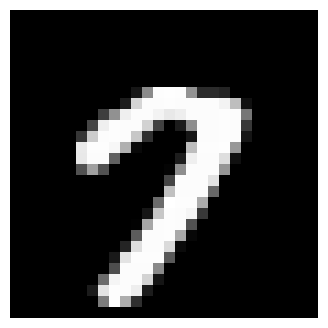

Dataset: mnist
Image: <local-home>\Desktop\ASSIGNMENT_4\demo_examples\mnist\good\good_index_7754_label_7_7.png
True class: 7
Raw model prediction: 7 (confidence=1.0000)
Synthetic model prediction: 7 (confidence=1.0000)


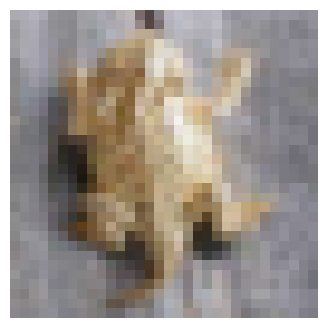

Dataset: cifar10
Image: <local-home>\Desktop\ASSIGNMENT_4\demo_examples\cifar10\bad\bad_index_5203_label_6_frog.png
True class: frog
Raw model prediction: cat (confidence=0.7560)
Synthetic model prediction: cat (confidence=0.6270)


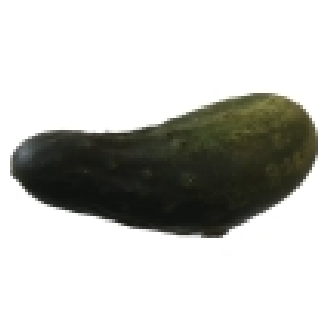

Dataset: fruits360
Image: <local-home>\Desktop\ASSIGNMENT_4\demo_examples\fruits360\good\good_index_17007_label_98_Cucumber_9.png
True class: Cucumber 9
Raw model prediction: Cucumber 9 (confidence=1.0000)
Synthetic model prediction: Cucumber 9 (confidence=0.9999)


In [88]:
run_demo("mnist", example_type="good")
run_demo("cifar10", example_type="bad")
run_demo("fruits360", example_type="good")